**Datasets:**

*Motor Vehicle Collisions – Vehicles:* https://data.cityofnewyork.us/PublicSafety/Motor-Vehicle-Collisions-Vehicles/bm4k-52h4/about_data
*Motor Vehicle Collisions – Crashes:* https://data.cityofnewyork.us/PublicSafety/Motor-Vehicle-Collisions-Crashes/h9gi-nx95/about_data

# Import necessary libraries

In [1]:
# For getting the data and converting to dataframe
import os
import json
import requests
from google.colab import userdata

# For data cleaning/analysis
import pandas as pd

# For data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# For machine learning/model training
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import StandardScaler
import numpy as np

# For clustering
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# For hiding warnings
import warnings

# Part 1: Loading and Cleaning the data

## 1A: Loading the Data from the Open Data website

In [2]:
from google.colab import userdata

# make account on NYC Open Data -> create app token in dev settings -> input 'app token' in Colab Secrets as 'NYC_APP_TOKEN'
token = userdata.get('NYC_APP_TOKEN')

# Updated the crash_date filter to fetch data from 2021-05-07 to 2026-05-05
vehicle_url = "https://data.cityofnewyork.us/api/v3/views/bm4k-52h4/query.json?query=SELECT%20collision_id%2C%20vehicle_type%2C%20vehicle_make%2C%20vehicle_year%2C%20vehicle_occupants%2C%20driver_sex%2C%20driver_license_status%2C%20pre_crash%2C%20point_of_impact%2C%20vehicle_damage%2C%20contributing_factor_1%20WHERE%20((%60crash_date%60%20%3E%20'2021-05-07')%20AND%20%60crash_date%60%20IS%20NOT%20NULL%20AND%20%60crash_date%60%20%3C%20'2026-05-05')"
crash_url   = "https://data.cityofnewyork.us/api/v3/views/h9gi-nx95/query.json?query=SELECT%20crash_date%2C%20crash_time%2C%20borough%2C%20zip_code%2C%20on_street_name%2C%20off_street_name%2C%20cross_street_name%2C%20number_of_persons_injured%2C%20number_of_persons_killed%2C%20number_of_pedestrians_injured%2C%20number_of_pedestrians_killed%2C%20number_of_cyclist_injured%2C%20number_of_cyclist_killed%2C%20number_of_motorist_injured%2C%20number_of_motorist_killed%2C%20contributing_factor_vehicle_1%2C%20collision_id%2C%20vehicle_type_code1%20WHERE%20((%60crash_date%60%20%3E%20'2021-05-07')%20AND%20%60crash_date%60%20IS%20NOT%20NULL%20AND%20%60crash_date%60%20%3C%20'2026-05-05')"

headers = {
    'X-App-Token': token
}

if os.path.exists('vehicle_snapshot.pkl') and os.path.exists('crash_snapshot.pkl'):
  vehicle_df = pd.read_pickle('vehicle_snapshot.pkl')
  crash_df = pd.read_pickle('crash_snapshot.pkl')
  print('Loaded from cache')
else:
  vehicle_response = requests.get(vehicle_url, headers=headers)
  crash_response = requests.get(crash_url, headers=headers)

  print(vehicle_response.status_code)
  print(crash_response.status_code)

  vehicle_json = vehicle_response.json()
  crash_json = crash_response.json()

  vehicle_df = pd.DataFrame(vehicle_json)
  crash_df = pd.DataFrame(crash_json)

  vehicle_df.to_pickle('vehicle_snapshot.pkl')
  crash_df.to_pickle('crash_snapshot.pkl')
  print('Pulled from API and cached')

200
200
Pulled from API and cached


##1B: Selecting the columns for vehicle-level analysis

In [3]:
# Only retain useful columns for vehicle-level analysis
vehicle_cols = [
    'collision_id',
    'vehicle_type',
    'vehicle_make',
    'vehicle_year',
    'driver_sex',
    'driver_license_status',
    'vehicle_occupants',
    'pre_crash',
    'point_of_impact',
    'vehicle_damage',
    'contributing_factor_1'
]

vehicle_clean = vehicle_df[vehicle_cols].copy()

# Only retain useful columns for crash-level, location, and intersection analysis
crash_cols = [
    'collision_id',
    'crash_date',
    'crash_time',
    'borough',
    'zip_code',
    'on_street_name',
    'off_street_name',
    'cross_street_name',
    'number_of_persons_injured',
    'number_of_persons_killed',
    'number_of_pedestrians_injured',
    'number_of_pedestrians_killed',
    'number_of_cyclist_injured',
    'number_of_cyclist_killed',
    'number_of_motorist_injured',
    'number_of_motorist_killed',
    'contributing_factor_vehicle_1',
    'vehicle_type_code1'
]


vehicle_clean = vehicle_df[vehicle_cols].copy()
crash_clean = crash_df[crash_cols].copy()

# renaming the columns for better readability and conciseness
vehicle_clean = vehicle_clean.rename(columns={
    'collision_id': 'collision_id',
    'vehicle_type': 'vehicle_type',
    'vehicle_make': 'make',
    'vehicle_year': 'year',
    'driver_sex': 'driver_sex',
    'driver_license_status': 'license_status',
    'vehicle_occupants': 'occupants',
    'pre_crash': 'pre_crash_action',
    'point_of_impact': 'impact_point',
    'vehicle_damage': 'damage',
    'contributing_factor_1': 'vehicle_factor'
})

crash_clean = crash_clean.rename(columns={
    'collision_id': 'collision_id',
    'crash_date': 'date',
    'crash_time': 'time',
    'borough': 'borough',
    'zip_code': 'zip',
    'latitude': 'lat',
    'longitude': 'lon',
    'on_street_name': 'street_on',
    'off_street_name': 'street_off',
    'cross_street_name': 'street_cross',

    'number_of_persons_injured': 'injured_total',
    'number_of_persons_killed': 'killed_total',

    'number_of_pedestrians_injured': 'injured_ped',
    'number_of_pedestrians_killed': 'killed_ped',

    'number_of_cyclist_injured': 'injured_cyclist',
    'number_of_cyclist_killed': 'killed_cyclist',

    'number_of_motorist_injured': 'injured_motorist',
    'number_of_motorist_killed': 'killed_motorist',

    'contributing_factor_vehicle_1': 'factor',
    'vehicle_type_code1': 'vehicle_type'
})

#print(vehicle_clean.columns)
#print(crash_clean.columns)

## 1C: Handling Missing Values

In [4]:
# For vehicle data, we keep rows as long as collision_id exists, because it is required for merging with the crash dataset.
vehicle_clean = vehicle_clean.dropna(subset=[
   'collision_id'
])

# Remove rows only when essential columns for analysis are missing.
# These columns (collision_id, date, time, injured_total, killed_total) are critical to identify each accident and measure accident severity.
# If any of these are missing, the data cannot be used for our analysis.
crash_clean = crash_clean.dropna(subset=[
   'collision_id',
   'date',
   'time',
   'injured_total',
   'killed_total'
])

# For categorical variables (e.g., borough, vehicle type, contributing factors)we do NOT drop missing values.
# Instead, we replace them with 'UNKNOWN' to preserve as much data as possible and still allow grouping and analysis later.
vehicle_clean['vehicle_type'] = vehicle_clean['vehicle_type'].fillna('UNKNOWN')
vehicle_clean['make'] = vehicle_clean['make'].fillna('UNKNOWN')
vehicle_clean['driver_sex'] = vehicle_clean['driver_sex'].fillna('UNKNOWN')
vehicle_clean['license_status'] = vehicle_clean['license_status'].fillna('UNKNOWN')
vehicle_clean['pre_crash_action'] = vehicle_clean['pre_crash_action'].fillna('UNKNOWN')
vehicle_clean['impact_point'] = vehicle_clean['impact_point'].fillna('UNKNOWN')
vehicle_clean['damage'] = vehicle_clean['damage'].fillna('UNKNOWN')
vehicle_clean['vehicle_factor'] = vehicle_clean['vehicle_factor'].fillna('UNKNOWN')


crash_clean['borough'] = crash_clean['borough'].fillna('UNKNOWN')
crash_clean['zip'] = crash_clean['zip'].fillna('UNKNOWN')
crash_clean['factor'] = crash_clean['factor'].fillna('UNKNOWN')
crash_clean['vehicle_type'] = crash_clean['vehicle_type'].fillna('UNKNOWN')

## 1D: Standardizing Text Columns

In [5]:
# Convert text columns to uppercase and remove extra spaces
# Vehicle text columns
vehicle_clean['vehicle_type'] = vehicle_clean['vehicle_type'].astype(str).str.upper().str.strip()
vehicle_clean['make'] = vehicle_clean['make'].astype(str).str.upper().str.strip()
vehicle_clean['driver_sex'] = vehicle_clean['driver_sex'].astype(str).str.upper().str.strip()
vehicle_clean['license_status'] = vehicle_clean['license_status'].astype(str).str.upper().str.strip()
vehicle_clean['pre_crash_action'] = vehicle_clean['pre_crash_action'].astype(str).str.upper().str.strip()
vehicle_clean['impact_point'] = vehicle_clean['impact_point'].astype(str).str.upper().str.strip()
vehicle_clean['damage'] = vehicle_clean['damage'].astype(str).str.upper().str.strip()
vehicle_clean['vehicle_factor'] = vehicle_clean['vehicle_factor'].astype(str).str.upper().str.strip()

# Crash text columns
crash_clean['borough'] = crash_clean['borough'].astype(str).str.upper().str.strip()
crash_clean['zip'] = crash_clean['zip'].astype(str).str.strip()
crash_clean['factor'] = crash_clean['factor'].astype(str).str.upper().str.strip()
crash_clean['vehicle_type'] = crash_clean['vehicle_type'].astype(str).str.upper().str.strip()

# Street columns for intersection analysis
crash_clean['street_on'] = crash_clean['street_on'].astype(str).str.upper().str.strip()
crash_clean['street_off'] = crash_clean['street_off'].astype(str).str.upper().str.strip()
crash_clean['street_cross'] = crash_clean['street_cross'].astype(str).str.upper().str.strip()

# Convert fake missing text back to real missing values
crash_clean['street_on'] = crash_clean['street_on'].replace(['NAN', 'NONE', ''], pd.NA)
crash_clean['street_off'] = crash_clean['street_off'].replace(['NAN', 'NONE', ''], pd.NA)
crash_clean['street_cross'] = crash_clean['street_cross'].replace(['NAN', 'NONE', ''], pd.NA)

##1E: Data Formatting

In [6]:
# Convert date column to datetime format.
# This allows us to extract year, month, day of week, and other time-based features later.
crash_clean['date'] = pd.to_datetime(crash_clean['date'], errors='coerce')

# Convert injury and fatality columns to numeric values.
# These columns are needed to measure crash severity.
severity_cols = [
    'injured_total',
    'killed_total',
    'injured_ped',
    'killed_ped',
    'injured_cyclist',
    'killed_cyclist',
    'injured_motorist',
    'killed_motorist'
]

for col in severity_cols:
    crash_clean[col] = pd.to_numeric(crash_clean[col], errors='coerce')

# Convert vehicle-level numeric columns.
# Year is the vehicle model year, and occupants is the number of people in the vehicle.
vehicle_clean['year'] = pd.to_numeric(vehicle_clean['year'], errors='coerce')
vehicle_clean['occupants'] = pd.to_numeric(vehicle_clean['occupants'], errors='coerce')

# Extract hour from crash time.
# This allows us to analyze whether crashes happen more often at certain times of day.
crash_clean['hour'] = pd.to_datetime(
    crash_clean['time'],
    format='%H:%M',
    errors='coerce'
).dt.hour

# Create a time period column for easier analysis.
# This groups individual hours into broader categories.
def get_time_period(hour):
    if pd.isna(hour):
        return 'UNKNOWN'
    elif 5 <= hour < 12:
        return 'MORNING'
    elif 12 <= hour < 17:
        return 'AFTERNOON'
    elif 17 <= hour < 21:
        return 'EVENING'
    else:
        return 'NIGHT'

crash_clean['time_period'] = crash_clean['hour'].apply(get_time_period)

# Create severity-related columns.
# Total casualties = injuries + fatalities.
crash_clean['total_casualties'] = (
    crash_clean['injured_total'].fillna(0)
    + crash_clean['killed_total'].fillna(0)
)

# Create fatal crash indicator.
# fatal_crash = 1 if at least one person was killed, otherwise 0.
crash_clean['fatal_crash'] = (
    crash_clean['killed_total'].fillna(0) > 0
).astype(int)

# Create weighted severity score.
# Fatalities are weighted more heavily than injuries.
crash_clean['severity_score'] = (
    crash_clean['killed_total'].fillna(0) * 5
    + crash_clean['injured_total'].fillna(0) * 1
)

# Create intersection indicator.
# If cross street exists, we treat the crash as occurring at or near an intersection.
crash_clean['is_intersection'] = crash_clean['street_cross'].notna().astype(int)

# Extract month
crash_clean['month'] = crash_clean['date'].dt.month

# Extract season
def get_season(month):
    if pd.isna(month):
        return 'UNKNOWN'
    elif month in [12, 1, 2]:
        return 'WINTER'
    elif month in [3, 4, 5]:
        return 'SPRING'
    elif month in [6, 7, 8]:
        return 'SUMMER'
    else:
        return 'FALL'

crash_clean['season'] = crash_clean['month'].apply(get_season)

# Extract day of week
crash_clean['day_of_week'] = crash_clean['date'].dt.day_name()

# Create weekend indicator
# weekday = 0, weekend = 1
crash_clean['is_weekend'] = (
    crash_clean['day_of_week'].isin(['Saturday', 'Sunday'])
).astype(int)

## 1F: Merging vehicle and crash datasets

In [7]:
# We merge the vehicle-level data with crash-level data using collision_id.
# This allows us to analyze how vehicle characteristics relate to crash severity.

merged_df_master = pd.merge(
    vehicle_clean,
    crash_clean,
    on='collision_id',
    how='inner',
    suffixes=('_vehicle', '_crash')
)

# --- Basic checks ---

# Check shapes before and after merge
print("Vehicle dataset shape:", vehicle_clean.shape)
print("Crash dataset shape:", crash_clean.shape)
print("Merged dataset shape:", merged_df_master.shape)

# Check how many unique crashes are included
print("\nUnique collisions:", merged_df_master['collision_id'].nunique())

# Check duplicate collision_ids (important because one crash can have multiple vehicles)
print("\nDuplicate collision IDs (top 5):")
print(merged_df_master['collision_id'].value_counts().head())

# --- Column and missing value checks ---

# Check column names
print("\nMerged columns:")
print(merged_df_master.columns)

# Check missing values after merge
print("\nMissing values after merge:")
print(merged_df_master.isnull().sum())

# Final Cleaning:
merged_df_master['year'] = merged_df_master['year'].fillna('UNKNOWN')
merged_df_master['occupants'] = merged_df_master['occupants'].fillna('UNKNOWN')
merged_df_master['street_on'] = merged_df_master['street_on'].fillna('UNKNOWN')
merged_df_master['street_off'] = merged_df_master['street_off'].fillna('UNKNOWN')
merged_df_master['street_cross'] = merged_df_master['street_cross'].fillna('UNKNOWN')

# Post Final Cleaning - check missing values:
print()
print("\nFinal check for missing values:")
print(merged_df_master.isnull().sum())

# --- Preview data ---

#display(merged_df_master)
print("\nCompleted merged dataset (head):")
merged_df_master.head(5)

Vehicle dataset shape: (970123, 11)
Crash dataset shape: (481599, 28)
Merged dataset shape: (970123, 38)

Unique collisions: 481522

Duplicate collision IDs (top 5):
collision_id
7404995503407c16bbd69931bcdfaee7    42
13738431cd203e14b0cf964386836816    40
4311ce2b38cedf206e02c33a332837af    22
34785ee577ab5521664dc141db642212    20
caa648a76f91dd47fbe6eb4a2295de53    19
Name: count, dtype: int64

Merged columns:
Index(['collision_id', 'vehicle_type_vehicle', 'make', 'year', 'driver_sex',
       'license_status', 'occupants', 'pre_crash_action', 'impact_point',
       'damage', 'vehicle_factor', 'date', 'time', 'borough', 'zip',
       'street_on', 'street_off', 'street_cross', 'injured_total',
       'killed_total', 'injured_ped', 'killed_ped', 'injured_cyclist',
       'killed_cyclist', 'injured_motorist', 'killed_motorist', 'factor',
       'vehicle_type_crash', 'hour', 'time_period', 'total_casualties',
       'fatal_crash', 'severity_score', 'is_intersection', 'month', 'season',
 

,collision_id,vehicle_type_vehicle,make,year,driver_sex,license_status,occupants,pre_crash_action,impact_point,damage,...,hour,time_period,total_casualties,fatal_crash,severity_score,is_intersection,month,season,day_of_week,is_weekend
0,5c661c5b2c99bd776e6c9d074bdfcadb,STATION WAGON/SPORT UTILITY VEHICLE,NISS -CAR/SUV,2025.0,F,LICENSED,1.0,GOING STRAIGHT AHEAD,RIGHT FRONT BUMPER,RIGHT FRONT BUMPER,...,11,MORNING,0,0,0,1,5,SPRING,Monday,0
1,fcbdc1cf1b08310f115eb06cf03570af,BUS,VANH,2007.0,M,LICENSED,1.0,GOING STRAIGHT AHEAD,RIGHT SIDE DOORS,RIGHT SIDE DOORS,...,6,MORNING,3,0,3,1,5,SPRING,Monday,0
2,86c34c442a281851adb0fb2991cb045b,SEDAN,UNKNOWN,UNKNOWN,UNKNOWN,UNKNOWN,1.0,GOING STRAIGHT AHEAD,RIGHT FRONT BUMPER,RIGHT FRONT BUMPER,...,3,NIGHT,0,0,0,0,5,SPRING,Monday,0
3,f7c15bffbd2e05e17c8b3c68faccf2f6,SEDAN,FORD -CAR/SUV,UNKNOWN,M,LICENSED,1.0,PARKED,CENTER BACK END,OTHER,...,16,AFTERNOON,1,0,1,1,5,SPRING,Monday,0
4,f9067e3b29c7cf216f5ea5b3ac550e7c,SEDAN,HOND -CAR/SUV,2025.0,M,LICENSED,1.0,PARKED,CENTER BACK END,LEFT REAR BUMPER,...,13,AFTERNOON,0,0,0,1,5,SPRING,Monday,0


# Part 2: Exploratory Data Analysis

## 2A: Count the number of crashes by Zip Code

In [8]:
# Calculate fatality rate per zip code
zip_fatality_rates = (
    merged_df_master[merged_df_master['zip'] != 'UNKNOWN']
    .groupby('zip')['fatal_crash']
    .mean()
    .reset_index(name='fatality_rate')
)

# Convert fatality rate to percentage for better readability
zip_fatality_rates['fatality_rate_percent'] = (zip_fatality_rates['fatality_rate'] * 100).round(2)

# Sort by fatality rate in descending order
zip_fatality_rates_sorted = (
    zip_fatality_rates.sort_values('fatality_rate_percent', ascending=False)
)

print("Top 25 Zip Codes by Fatality Rate:")
display(zip_fatality_rates_sorted.head(25))

Top 25 Zip Codes by Fatality Rate:


,zip,fatality_rate,fatality_rate_percent
45,10069,0.008475,0.85
111,10464,0.006424,0.64
46,10075,0.005587,0.56
131,11105,0.005512,0.55
224,11693,0.005450,0.54
161,11230,0.004872,0.49
35,10037,0.004870,0.49
31,10033,0.004540,0.45
38,10040,0.004392,0.44
136,11204,0.004195,0.42


In [9]:
# Crashes per zip code
zip_counts = (
    crash_clean[crash_clean['zip'] != 'UNKNOWN']
    .groupby('zip')['collision_id']
    .nunique()
    .reset_index(name='crash_count')
    .sort_values('crash_count', ascending=False)
)

# Top 25 zip codes
print(zip_counts.head(25))

       zip  crash_count
139  11207         8274
167  11236         5557
140  11208         5447
144  11212         5276
135  11203         4883
165  11234         4594
198  11385         4455
158  11226         4361
187  11368         4190
127  11101         4167
164  11233         4034
138  11206         3981
134  11201         3901
143  11211         3800
152  11220         3622
2    10002         3522
27   10029         3476
219  11434         3383
104  10457         3375
114  10467         3345
195  11377         3297
192  11373         3260
153  11221         3150
105  10458         3149
149  11217         3133


/tmp/ipykernel_11799/3999442693.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='crash_count', y='zip', data=top_25_zip_codes, palette='viridis')


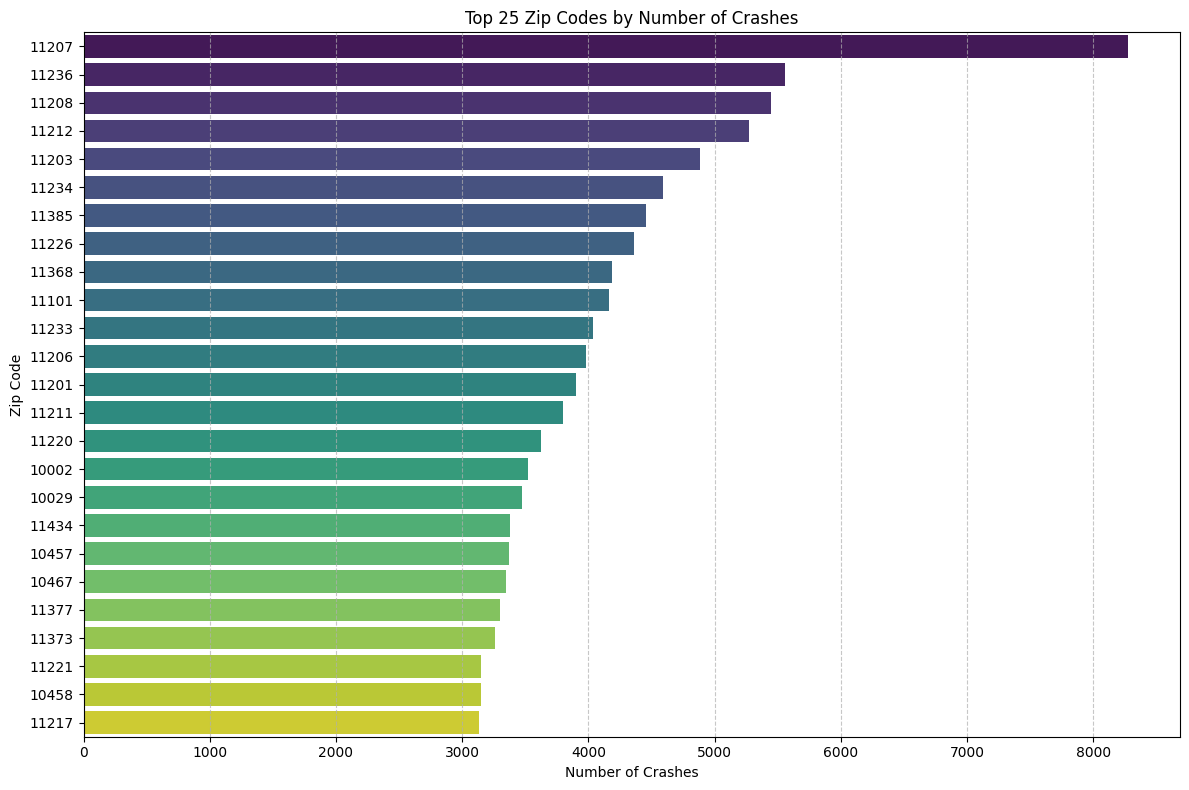

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# Get the top 25 zip codes
top_25_zip_codes = zip_counts.head(25)

# Create a horizontal bar chart
plt.figure(figsize=(12, 8))
sns.barplot(x='crash_count', y='zip', data=top_25_zip_codes, palette='viridis')
plt.title('Top 25 Zip Codes by Number of Crashes')
plt.xlabel('Number of Crashes')
plt.ylabel('Zip Code')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

/tmp/ipykernel_11799/4017913367.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='fatality_rate_percent', y='zip', data=top_25_fatal_zips, palette='magma')


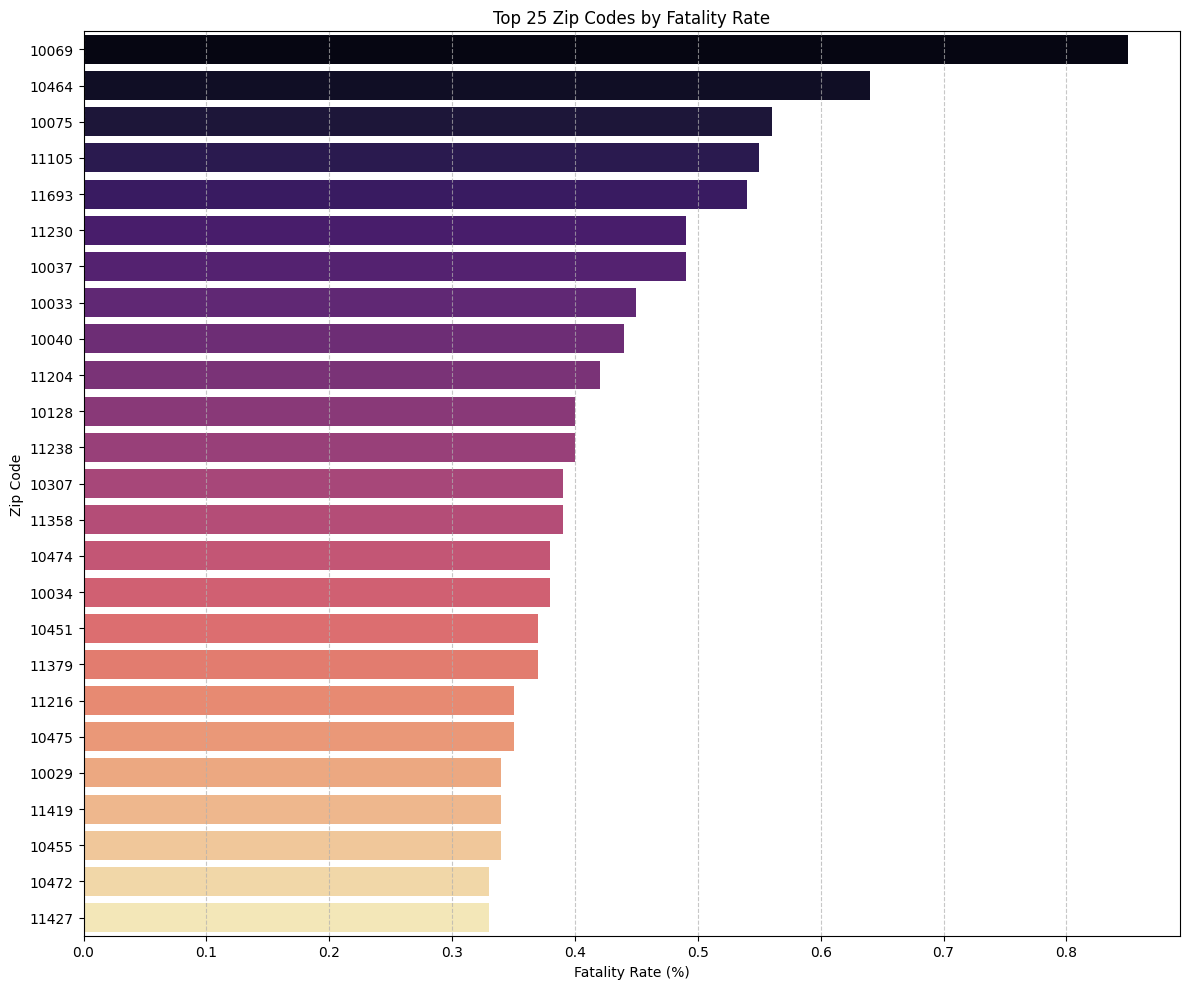

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# Get the top 25 zip codes by fatality rate
top_25_fatal_zips = zip_fatality_rates_sorted.head(25)

# Create a horizontal bar chart
plt.figure(figsize=(12, 10))
sns.barplot(x='fatality_rate_percent', y='zip', data=top_25_fatal_zips, palette='magma')
plt.title('Top 25 Zip Codes by Fatality Rate')
plt.xlabel('Fatality Rate (%)')
plt.ylabel('Zip Code')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

## 2B: Count Crashes by Season and Month

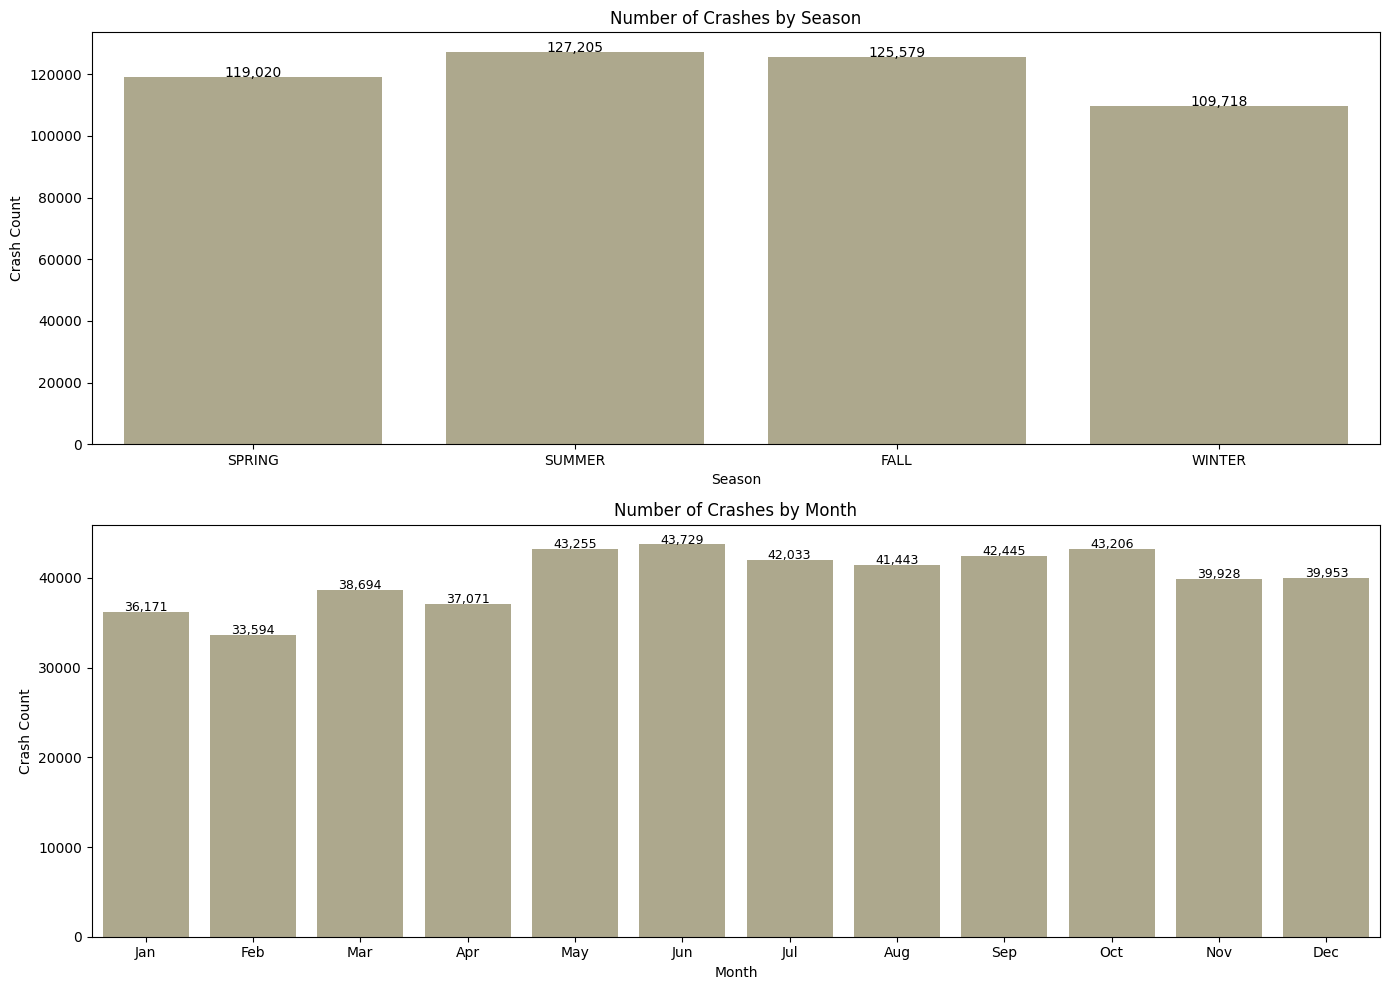

In [12]:
# Crash Count by Season and Month

# Use 'nunique’ for count instead of 'count'
# It allows us to count more than 2 vehicles involved in an accident as a single accident.
season_counts = (
    merged_df_master
    .groupby('season')['collision_id']
    .nunique()
    .reset_index(name='crash_count')
)

# Fix season order
season_order = ['SPRING', 'SUMMER', 'FALL', 'WINTER']


# Crash Count by Month

# Use  'nunique’ for count instead of 'count'.
# It allows us to count more than 2 vehicles involved in an accident as a single accident.
month_counts = (
    merged_df_master
    .groupby('month')['collision_id']
    .nunique()
    .reset_index(name='crash_count')
)

# Convert to month name
month_names = {
    1:'Jan', 2:'Feb', 3:'Mar', 4:'Apr',
    5:'May', 6:'Jun', 7:'Jul', 8:'Aug',
    9:'Sep', 10:'Oct', 11:'Nov', 12:'Dec'
}

month_counts['month_name'] = month_counts['month'].map(month_names)

# Fix month order
month_order = [
    'Jan', 'Feb', 'Mar', 'Apr',
    'May', 'Jun', 'Jul', 'Aug',
    'Sep', 'Oct', 'Nov', 'Dec'
]

# Create Subplots
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# 1. Number of Crashes by Season
ax1 = sns.barplot(
    data=season_counts,
    x='season',
    y='crash_count',
    order=season_order,
    color='#B2AC88',
    ax=axes[0]
)

# Add value to the graph
for i, v in enumerate(
    season_counts.set_index('season').loc[season_order]['crash_count']
):
    ax1.text(
        i,
        v + 100,
        f'{v:,}',
        ha='center',
        fontsize=10
    )

axes[0].set_title('Number of Crashes by Season')
axes[0].set_xlabel('Season')
axes[0].set_ylabel('Crash Count')

# 2. Number of Crashes by Month
ax2 = sns.barplot(
    data=month_counts,
    x='month_name',
    y='crash_count',
    order=month_order,
    color='#B2AC88',
    ax=axes[1]
)

# Add value to the graph
for i, v in enumerate(
    month_counts.set_index('month_name').loc[month_order]['crash_count']
):
    ax2.text(
        i,
        v + 100,
        f'{v:,}',
        ha='center',
        fontsize=9
    )

axes[1].set_title('Number of Crashes by Month')
axes[1].set_xlabel('Month')
axes[1].set_ylabel('Crash Count')

# Layout
plt.tight_layout()
plt.show()

## 2C: Find the average daily crashes by Season/Month and Weekday/Weekend

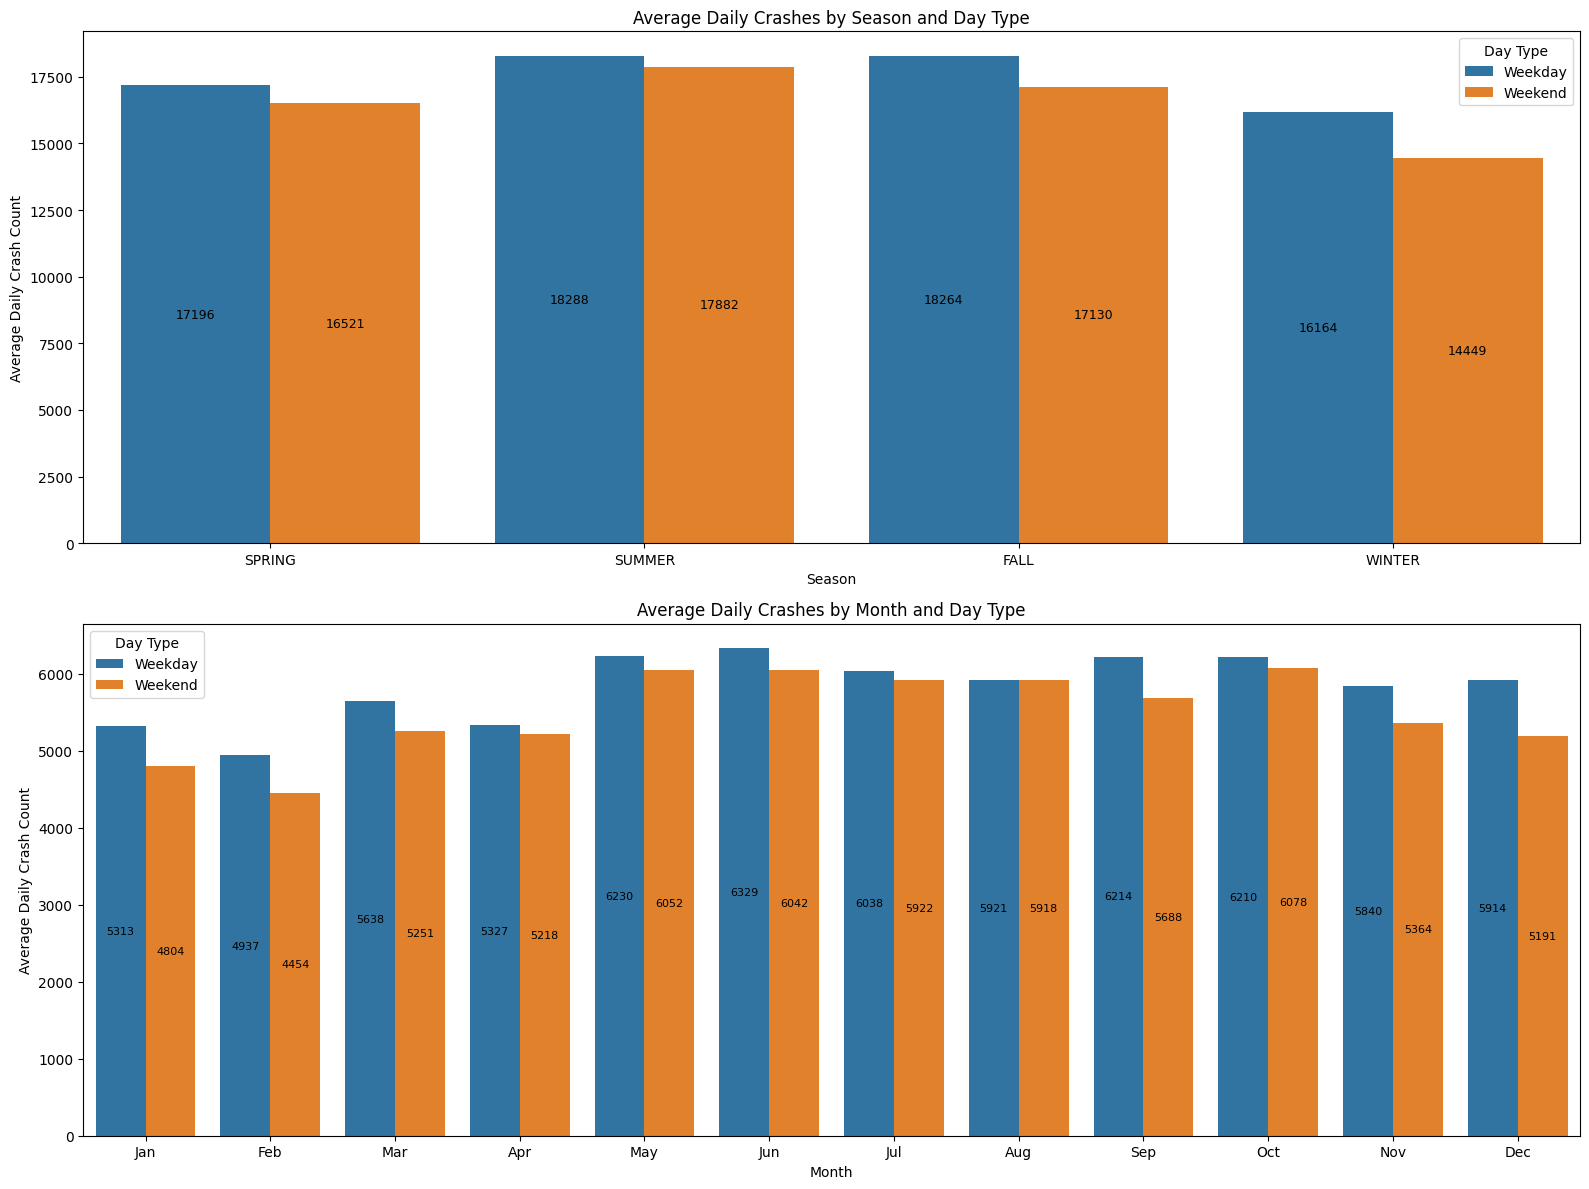

In [13]:
# Average Daily Crashes by Season/Month and Weekday/Weekend

week_analysis = merged_df_master.copy()

# Weekday / Weekend label
week_analysis['day_type'] = week_analysis['is_weekend'].map({
    0: 'Weekday',
    1: 'Weekend'
})

# Convert to month name
month_names = {
    1:'Jan', 2:'Feb', 3:'Mar', 4:'Apr',
    5:'May', 6:'Jun', 7:'Jul', 8:'Aug',
    9:'Sep', 10:'Oct', 11:'Nov', 12:'Dec'
}

week_analysis['month_name'] = week_analysis['month'].map(month_names)

# Fix season and month orders
season_order = ['SPRING', 'SUMMER', 'FALL', 'WINTER']

month_order = [
    'Jan', 'Feb', 'Mar', 'Apr',
    'May', 'Jun', 'Jul', 'Aug',
    'Sep', 'Oct', 'Nov', 'Dec'
]

day_order = ['Weekday', 'Weekend']

# Season and Weekday/Weekend
season_week_ct = (
    week_analysis
    .groupby(['season', 'day_type'])['collision_id']
    .nunique()
    .reset_index(name='crash_count')
)

# To compare weekday and weekend, we normalize data
season_week_ct['daily_average'] = season_week_ct.apply(
    lambda row: row['crash_count'] / 5 if row['day_type'] == 'Weekday'
    else row['crash_count'] / 2,
    axis=1
)

season_week_ct['season'] = pd.Categorical(
    season_week_ct['season'],
    categories=season_order,
    ordered=True
)

season_week_ct['day_type'] = pd.Categorical(
    season_week_ct['day_type'],
    categories=day_order,
    ordered=True
)

season_week_ct = season_week_ct.sort_values(['season', 'day_type'])

# Month and Weekday/Weekend
month_week_ct = (
    week_analysis
    .groupby(['month_name', 'day_type'])['collision_id']
    .nunique()
    .reset_index(name='crash_count')
)

# Normalize
month_week_ct['daily_average'] = month_week_ct.apply(
    lambda row: row['crash_count'] / 5 if row['day_type'] == 'Weekday'
    else row['crash_count'] / 2,
    axis=1
)

month_week_ct['month_name'] = pd.Categorical(
    month_week_ct['month_name'],
    categories=month_order,
    ordered=True
)

month_week_ct['day_type'] = pd.Categorical(
    month_week_ct['day_type'],
    categories=day_order,
    ordered=True
)

month_week_ct = month_week_ct.sort_values(['month_name', 'day_type'])

# Plot together
fig, axes = plt.subplots(2, 1, figsize=(16, 12))

# Season graph
ax1 = sns.barplot(
    data=season_week_ct,
    x='season',
    y='daily_average',
    hue='day_type',
    order=season_order,
    hue_order=day_order,
    ax=axes[0]
)

# Add value to the graph
for container in ax1.containers:
    ax1.bar_label(
        container,
        fmt='%.0f',
        label_type='center',
        fontsize=9
    )

axes[0].set_title('Average Daily Crashes by Season and Day Type')
axes[0].set_xlabel('Season')
axes[0].set_ylabel('Average Daily Crash Count')
axes[0].legend(title='Day Type')

# Month graph
ax2 = sns.barplot(
    data=month_week_ct,
    x='month_name',
    y='daily_average',
    hue='day_type',
    order=month_order,
    hue_order=day_order,
    ax=axes[1]
)

# Add value to the graph
for container in ax2.containers:
    ax2.bar_label(
        container,
        fmt='%.0f',
        label_type='center',
        fontsize=8
    )

axes[1].set_title('Average Daily Crashes by Month and Day Type')
axes[1].set_xlabel('Month')
axes[1].set_ylabel('Average Daily Crash Count')
axes[1].legend(title='Day Type')

# Layout
plt.tight_layout()
plt.show()

## 2D: Find contributing Factors by season and month

/tmp/ipykernel_11799/814490632.py:57: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby('season')
/tmp/ipykernel_11799/814490632.py:91: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby('month_name')


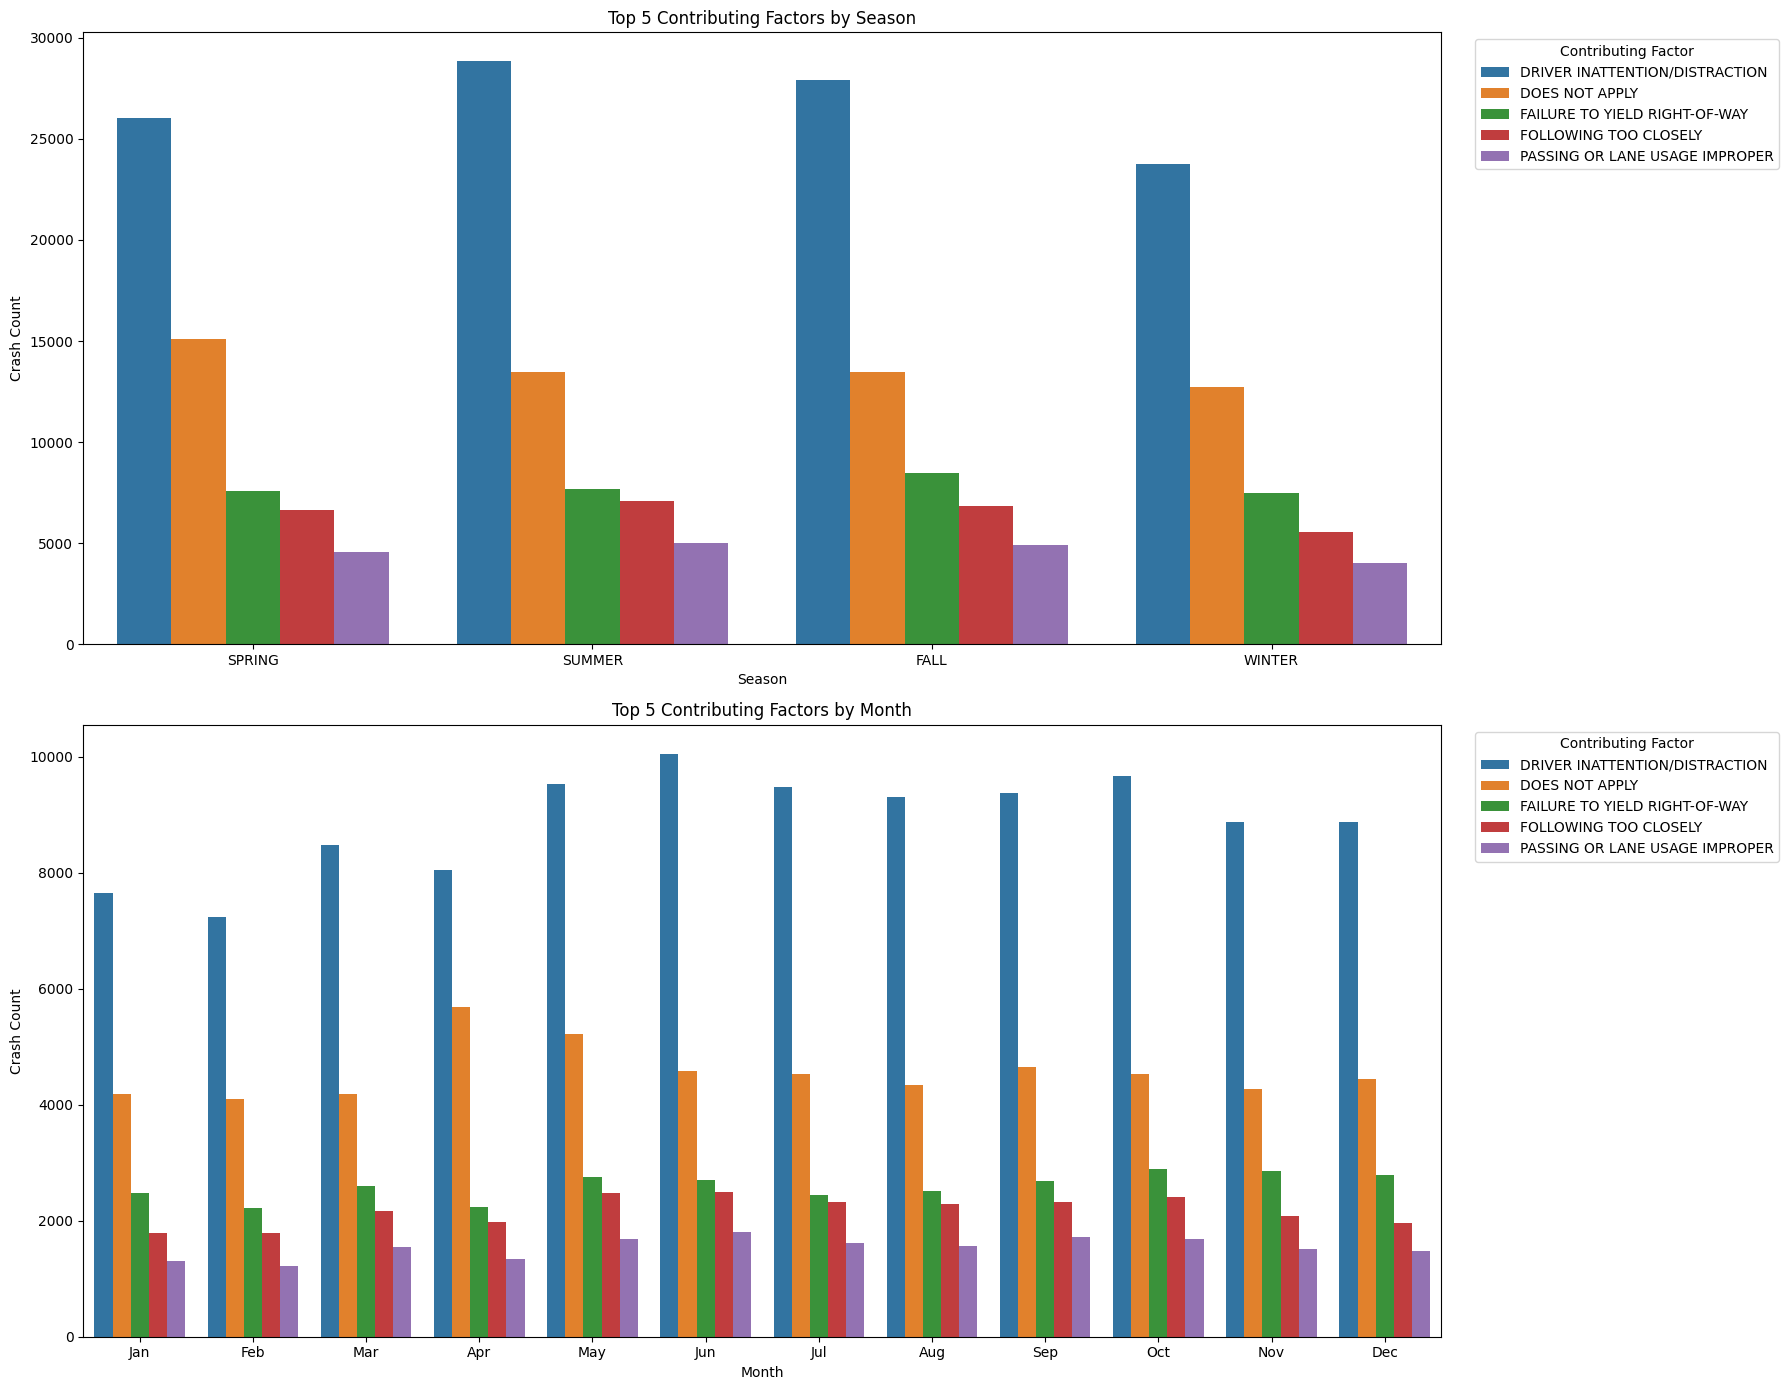

In [14]:
# Top 5 Contributing Factors by Season + Top 5 Contributing Factors by Month

# Fix Season and Month Order
season_order = ['SPRING', 'SUMMER', 'FALL', 'WINTER']

month_order = [
    'Jan', 'Feb', 'Mar', 'Apr',
    'May', 'Jun', 'Jul', 'Aug',
    'Sep', 'Oct', 'Nov', 'Dec'
]

# Convert to month names
month_names = {
    1:'Jan', 2:'Feb', 3:'Mar', 4:'Apr',
    5:'May', 6:'Jun', 7:'Jul', 8:'Aug',
    9:'Sep', 10:'Oct', 11:'Nov', 12:'Dec'
}
# Copy the dataset for month analysis:
month_vs_crashes = merged_df_master.copy()
# Add month_name column
month_vs_crashes['month_name'] = (
    month_vs_crashes['month'].map(month_names)
)


# Top 5 Contributing Factors by Season
# Remove UNKNOWN and UNSPECIFIED
#season_vs_crashes = merged_df_master.copy()
season_factor_analysis = merged_df_master[
    (merged_df_master['factor'] != 'UNKNOWN') &
    (merged_df_master['factor'] != 'UNSPECIFIED')
].copy()


# Count unique crashes: Use 'nunique' instead of 'count'.
season_factor_counts = (
    season_factor_analysis
    .groupby(['season', 'factor'])['collision_id']
    .nunique()
    .reset_index(name='crash_count')
)

# Set season order
season_factor_counts['season'] = pd.Categorical(
    season_factor_counts['season'],
    categories=season_order,
    ordered=True
)

# Get Top 5 contributing factors within each season
top5_season_factors = (
    season_factor_counts
    .sort_values(
        ['season', 'crash_count'],
        ascending=[True, False]
    )
    .groupby('season')
    .head(5)
)

# Top 5 contributing factors by Month
# Remove UNKNOWN and UNSPEFICIED
month_factor_analysis = month_vs_crashes[
    (month_vs_crashes['factor'] != 'UNKNOWN') &
    (month_vs_crashes['factor'] != 'UNSPECIFIED')
].copy()


# Count unique crashes:Use 'nunique' instead of 'count'.
month_factor_counts = (
    month_factor_analysis
    .groupby(['month_name', 'factor'])['collision_id']
    .nunique()
    .reset_index(name='crash_count')
)

# Set month order
month_factor_counts['month_name'] = pd.Categorical(
    month_factor_counts['month_name'],
    categories=month_order,
    ordered=True
)

# Get Top 5 Contributing factors within each month
top5_month_factors = (
    month_factor_counts
    .sort_values(
        ['month_name', 'crash_count'],
        ascending=[True, False]
    )
    .groupby('month_name')
    .head(5)
)

# Create Subplots
fig, axes = plt.subplots(
    2, 1,
    figsize=(18, 14)
)

# Graph 1: Top5 contributing factors by Season
sns.barplot(
    data=top5_season_factors,
    x='season',
    y='crash_count',
    hue='factor',
    order=season_order,
    ax=axes[0]
)

axes[0].set_title('Top 5 Contributing Factors by Season')
axes[0].set_xlabel('Season')
axes[0].set_ylabel('Crash Count')

axes[0].legend(
    title='Contributing Factor',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)

# Graph 2: Top5 contributing factors by Month
sns.barplot(
    data=top5_month_factors,
    x='month_name',
    y='crash_count',
    hue='factor',
    order=month_order,
    ax=axes[1]
)

axes[1].set_title('Top 5 Contributing Factors by Month')
axes[1].set_xlabel('Month')
axes[1].set_ylabel('Crash Count')

axes[1].legend(
    title='Contributing Factor',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)

# Layout
plt.tight_layout()
plt.show()

## 2E: Find Fatal Crash Rate and Severity Score by Season and Month

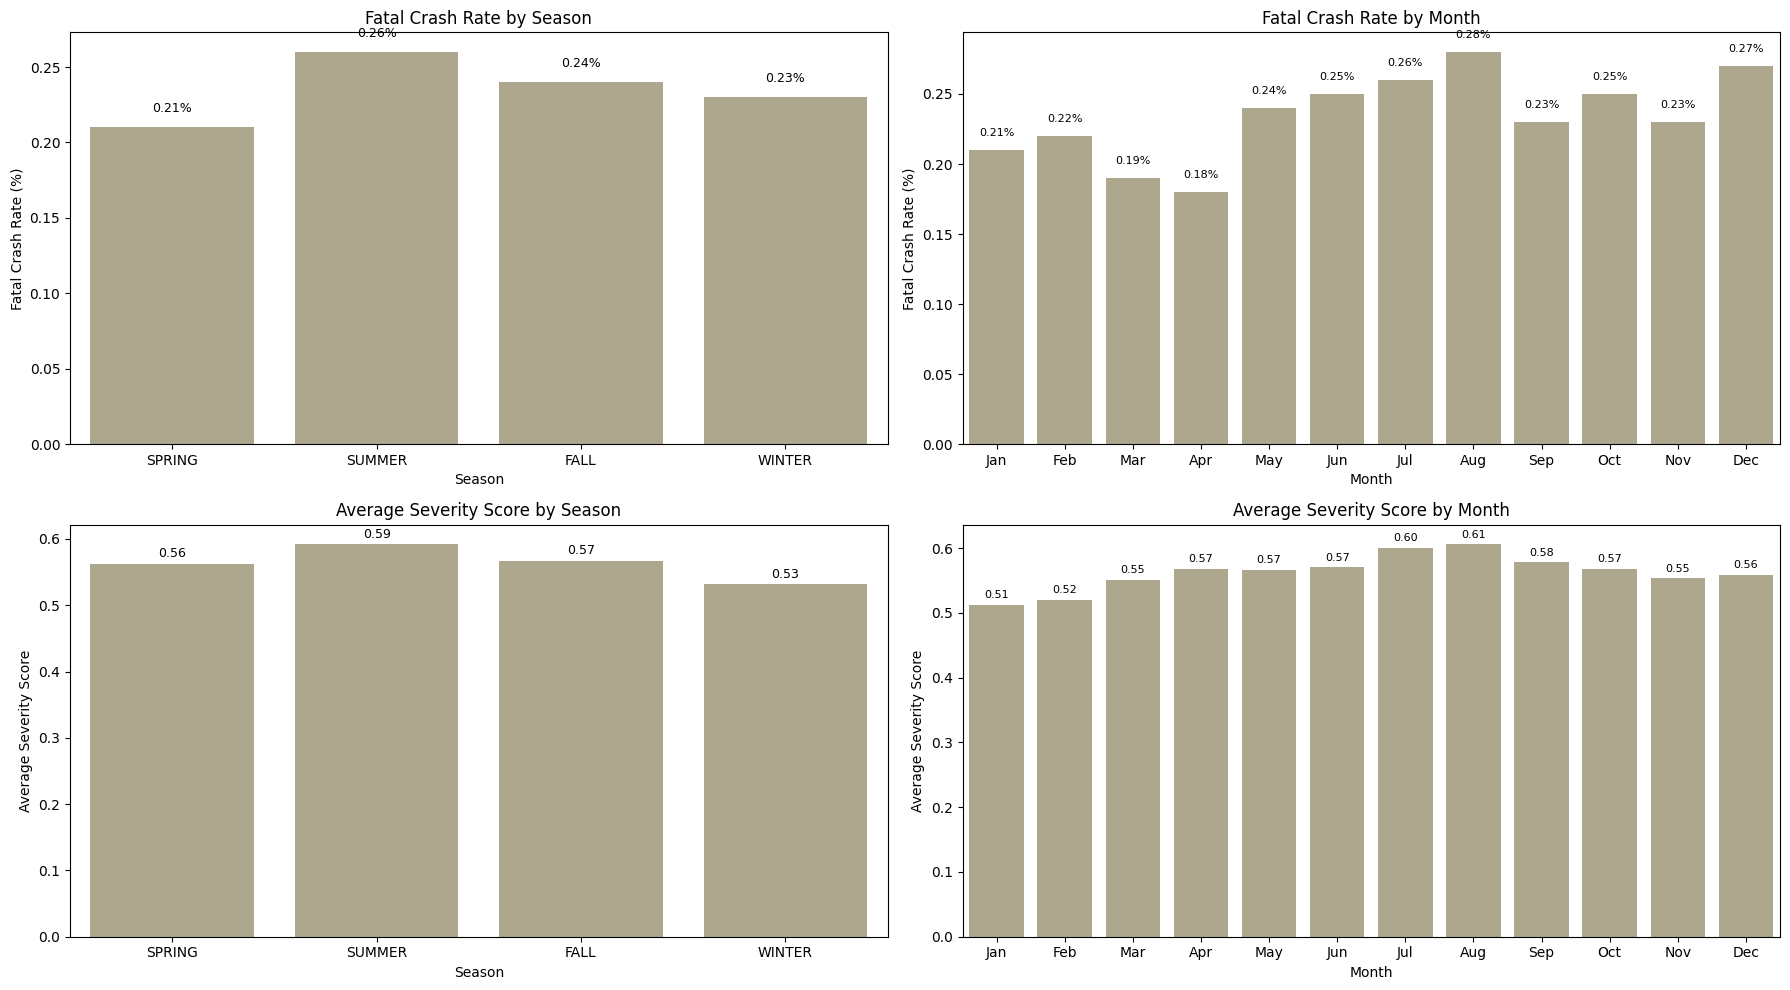

In [15]:
# Fatal crash rate and Severity Score by season and month

season_vs_crashes = merged_df_master.copy()

# Fix month names orders
month_names = {
    1:'Jan', 2:'Feb', 3:'Mar', 4:'Apr',
    5:'May', 6:'Jun', 7:'Jul', 8:'Aug',
    9:'Sep', 10:'Oct', 11:'Nov', 12:'Dec'
}

season_order = ['SPRING', 'SUMMER', 'FALL', 'WINTER']
month_order = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
               'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

# Season Fatal Rate
season_fatal_rate = (
    season_vs_crashes
    .groupby('season')['fatal_crash']
    .mean()
    .reset_index(name='fatal_rate')
)

# Convert to %
season_fatal_rate['fatal_rate_percent'] = (
    season_fatal_rate['fatal_rate'] * 100
).round(2)


# Month Fatal Rate
month_fatal_rate = (
    month_vs_crashes
    .groupby('month')['fatal_crash']
    .mean()
    .reset_index(name='fatal_rate')
)

# Convert to %
month_fatal_rate['fatal_rate_percent'] = (
    month_fatal_rate['fatal_rate'] * 100
).round(2)

month_fatal_rate['month_name'] = month_fatal_rate['month'].map(month_names)

# Season Severity Score
season_severity = (
    season_vs_crashes
    .groupby('season')['severity_score']
    .mean()
    .reset_index(name='avg_severity')
)

# Month Severity Score
month_severity = (
    month_vs_crashes
    .groupby('month')['severity_score']
    .mean()
    .reset_index(name='avg_severity')
)

month_severity['month_name'] = month_severity['month'].map(month_names)

# Create 2 x 2 Subplots
fig, axes = plt.subplots(2, 2, figsize=(18, 10))

# 1. Fatal Rate by Season
ax1 = sns.barplot(
    data=season_fatal_rate,
    x='season',
    y='fatal_rate_percent',
    order=season_order,
    color='#B2AC88',
    ax=axes[0, 0]
)

# Add value on the graph
for i, v in enumerate(season_fatal_rate.set_index('season').loc[season_order]['fatal_rate_percent']):
    ax1.text(i, v + 0.01, f'{v:.2f}%', ha='center', fontsize=9)

axes[0, 0].set_title('Fatal Crash Rate by Season')
axes[0, 0].set_xlabel('Season')
axes[0, 0].set_ylabel('Fatal Crash Rate (%)')

# 2. Fatal Rate by Month
ax2 = sns.barplot(
    data=month_fatal_rate,
    x='month_name',
    y='fatal_rate_percent',
    order=month_order,
    color='#B2AC88',
    ax=axes[0, 1]
)

# Add value on the graph
for i, v in enumerate(month_fatal_rate.set_index('month_name').loc[month_order]['fatal_rate_percent']):
    ax2.text(i, v + 0.01, f'{v:.2f}%', ha='center', fontsize=8)

axes[0, 1].set_title('Fatal Crash Rate by Month')
axes[0, 1].set_xlabel('Month')
axes[0, 1].set_ylabel('Fatal Crash Rate (%)')

# 3. Severity Score by Season
ax3 = sns.barplot(
    data=season_severity,
    x='season',
    y='avg_severity',
    order=season_order,
    color='#B2AC88',
    ax=axes[1, 0]
)

# Add value on the graph
for i, v in enumerate(season_severity.set_index('season').loc[season_order]['avg_severity']):
    ax3.text(i, v + 0.01, f'{v:.2f}', ha='center', fontsize=9)

axes[1, 0].set_title('Average Severity Score by Season')
axes[1, 0].set_xlabel('Season')
axes[1, 0].set_ylabel('Average Severity Score')

# 4. Severity Score by Month
ax4 = sns.barplot(
    data=month_severity,
    x='month_name',
    y='avg_severity',
    order=month_order,
    color='#B2AC88',
    ax=axes[1, 1]
)

# Add value on the graph
for i, v in enumerate(month_severity.set_index('month_name').loc[month_order]['avg_severity']):
    ax4.text(i, v + 0.01, f'{v:.2f}', ha='center', fontsize=8)

axes[1, 1].set_title('Average Severity Score by Month')
axes[1, 1].set_xlabel('Month')
axes[1, 1].set_ylabel('Average Severity Score')

# Layout
plt.tight_layout()
plt.show()

## 2F Fatal Rate and Severity Score by Season/Month and Day Type

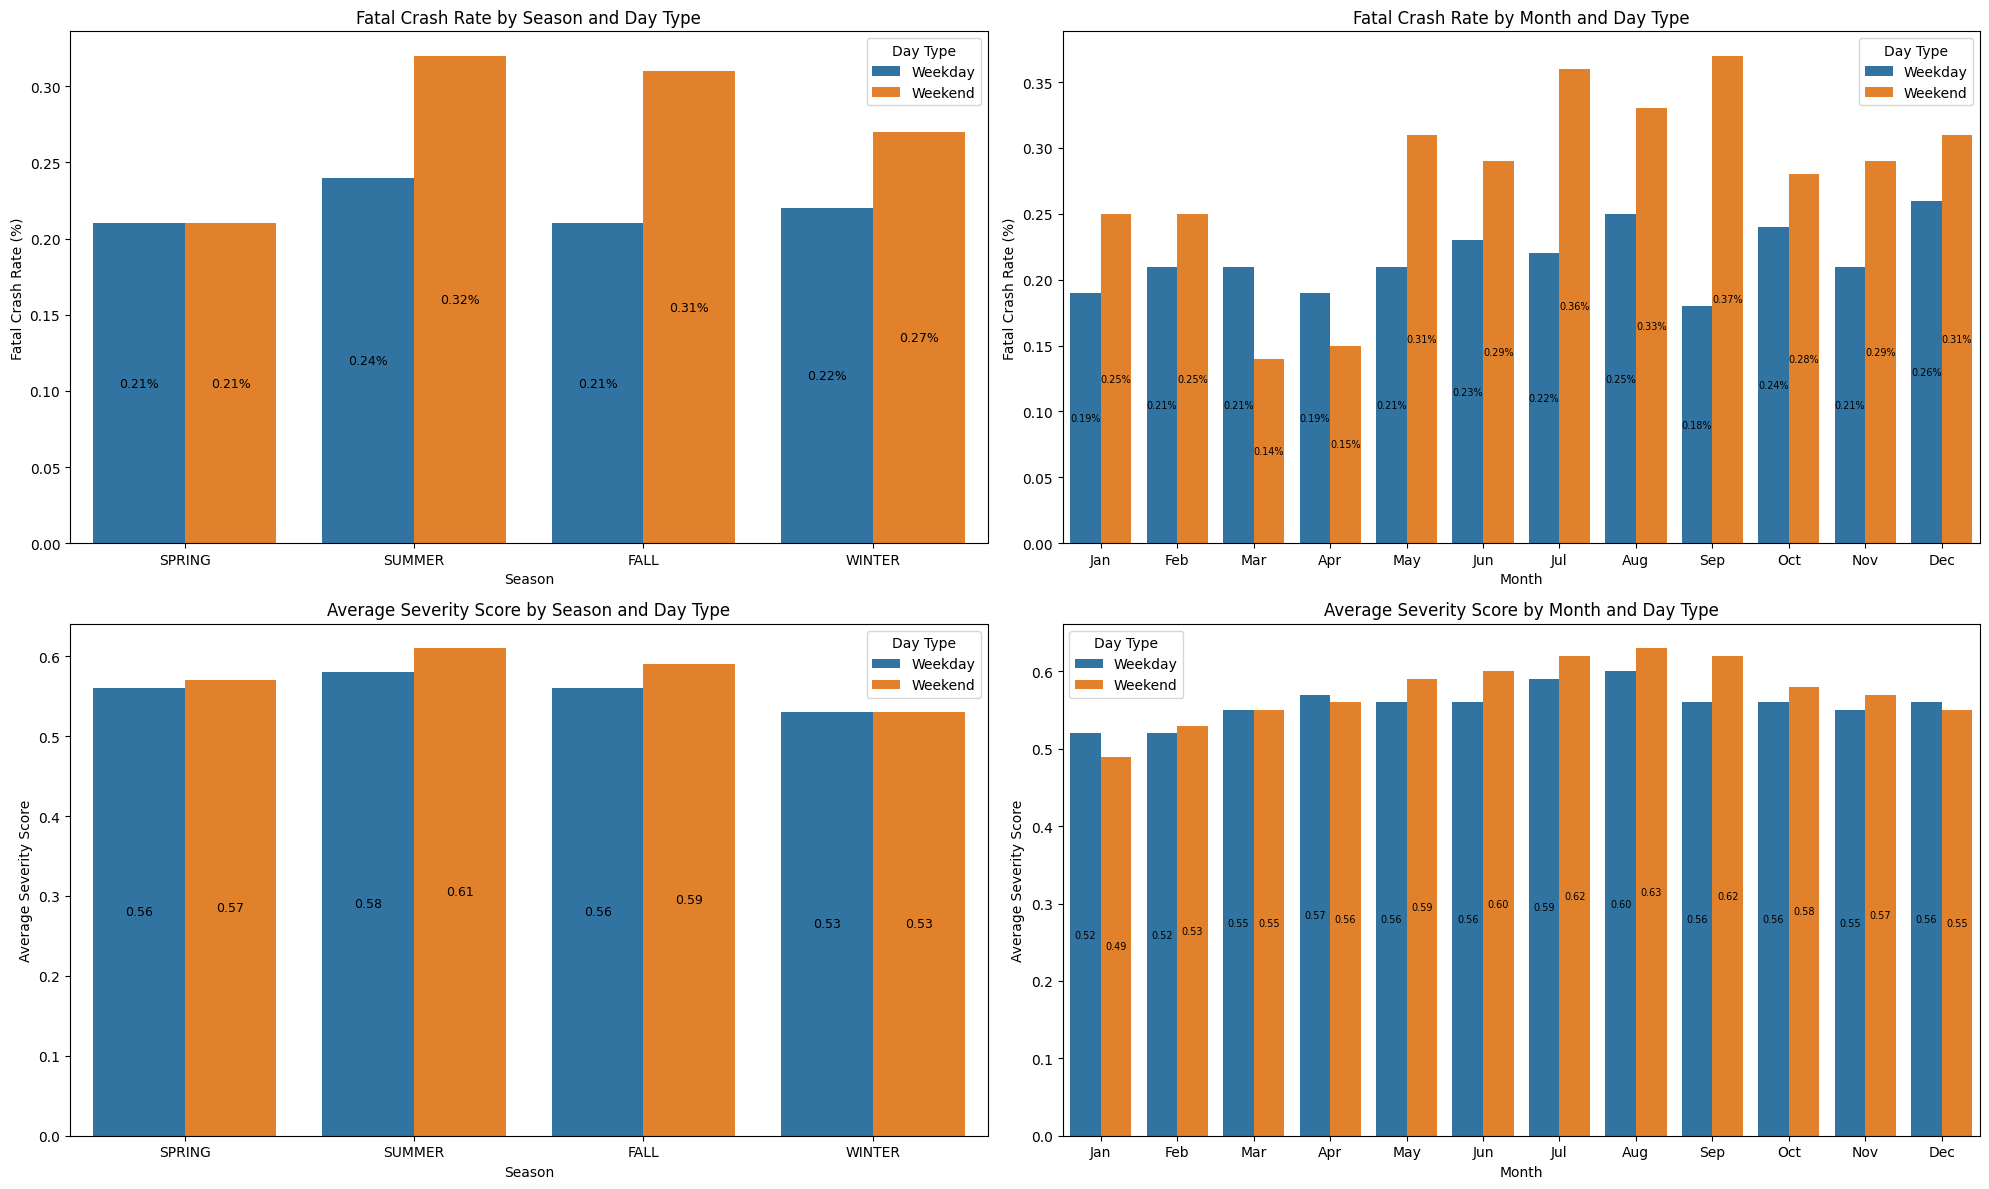

In [16]:
# Fatal Rate and Severity Score by Season/Month and Day Type (Weekday and Weekend)

severity_week_analysis = merged_df_master.copy()

# Weekday / Weekend label
severity_week_analysis['day_type'] = severity_week_analysis['is_weekend'].map({
    0: 'Weekday',
    1: 'Weekend'
})

# Convert to month name
month_names = {
    1:'Jan', 2:'Feb', 3:'Mar', 4:'Apr',
    5:'May', 6:'Jun', 7:'Jul', 8:'Aug',
    9:'Sep', 10:'Oct', 11:'Nov', 12:'Dec'
}

severity_week_analysis['month_name'] = (
    severity_week_analysis['month'].map(month_names)
)

# Fis season and month orders
season_order = ['SPRING', 'SUMMER', 'FALL', 'WINTER']

month_order = [
    'Jan', 'Feb', 'Mar', 'Apr',
    'May', 'Jun', 'Jul', 'Aug',
    'Sep', 'Oct', 'Nov', 'Dec'
]

day_order = ['Weekday', 'Weekend']

# 1. Fatal Rate by Season
season_week_fatal = (
    severity_week_analysis
    .groupby(['season', 'day_type'])['fatal_crash']
    .mean()
    .reset_index(name='fatal_rate')
)

# Convert to %
season_week_fatal['fatal_rate_percent'] = (
    season_week_fatal['fatal_rate'] * 100
).round(2)

season_week_fatal['season'] = pd.Categorical(
    season_week_fatal['season'],
    categories=season_order,
    ordered=True
)

season_week_fatal['day_type'] = pd.Categorical(
    season_week_fatal['day_type'],
    categories=day_order,
    ordered=True
)

season_week_fatal = season_week_fatal.sort_values(['season', 'day_type'])

# 2. Fatal Rate by Month
month_week_fatal = (
    severity_week_analysis
    .groupby(['month_name', 'day_type'])['fatal_crash']
    .mean()
    .reset_index(name='fatal_rate')
)

# Convert to %
month_week_fatal['fatal_rate_percent'] = (
    month_week_fatal['fatal_rate'] * 100
).round(2)

month_week_fatal['month_name'] = pd.Categorical(
    month_week_fatal['month_name'],
    categories=month_order,
    ordered=True
)

month_week_fatal['day_type'] = pd.Categorical(
    month_week_fatal['day_type'],
    categories=day_order,
    ordered=True
)

month_week_fatal = month_week_fatal.sort_values(['month_name', 'day_type'])

# 3. Severity Score by Season
season_week_severity = (
    severity_week_analysis
    .groupby(['season', 'day_type'])['severity_score']
    .mean()
    .reset_index(name='avg_severity')
)

season_week_severity['avg_severity'] = (
    season_week_severity['avg_severity'].round(2)
)

season_week_severity['season'] = pd.Categorical(
    season_week_severity['season'],
    categories=season_order,
    ordered=True
)

season_week_severity['day_type'] = pd.Categorical(
    season_week_severity['day_type'],
    categories=day_order,
    ordered=True
)

season_week_severity = season_week_severity.sort_values(['season', 'day_type'])

# 4. Severity Score by Month
month_week_severity = (
    severity_week_analysis
    .groupby(['month_name', 'day_type'])['severity_score']
    .mean()
    .reset_index(name='avg_severity')
)

month_week_severity['avg_severity'] = (
    month_week_severity['avg_severity'].round(2)
)

month_week_severity['month_name'] = pd.Categorical(
    month_week_severity['month_name'],
    categories=month_order,
    ordered=True
)

month_week_severity['day_type'] = pd.Categorical(
    month_week_severity['day_type'],
    categories=day_order,
    ordered=True
)

month_week_severity = month_week_severity.sort_values(['month_name', 'day_type'])

# Create 2 x 2 Subplots
fig, axes = plt.subplots(2, 2, figsize=(20, 12))

# Graph 1: Fatal Rate by Season
ax1 = sns.barplot(
    data=season_week_fatal,
    x='season',
    y='fatal_rate_percent',
    hue='day_type',
    order=season_order,
    hue_order=day_order,
    ax=axes[0, 0]
)

# Add value to the graph
for container in ax1.containers:
    ax1.bar_label(
        container,
        fmt='%.2f%%',
        label_type='center',
        fontsize=9
    )

axes[0, 0].set_title('Fatal Crash Rate by Season and Day Type')
axes[0, 0].set_xlabel('Season')
axes[0, 0].set_ylabel('Fatal Crash Rate (%)')
axes[0, 0].legend(title='Day Type')

# Graph 2: Fatal Rate by Month
ax2 = sns.barplot(
    data=month_week_fatal,
    x='month_name',
    y='fatal_rate_percent',
    hue='day_type',
    order=month_order,
    hue_order=day_order,
    ax=axes[0, 1]
)

# Add value to the graph
for container in ax2.containers:
    ax2.bar_label(
        container,
        fmt='%.2f%%',
        label_type='center',
        fontsize=7
    )

axes[0, 1].set_title('Fatal Crash Rate by Month and Day Type')
axes[0, 1].set_xlabel('Month')
axes[0, 1].set_ylabel('Fatal Crash Rate (%)')
axes[0, 1].legend(title='Day Type')

# Graph 3: Severity Score by Season
ax3 = sns.barplot(
    data=season_week_severity,
    x='season',
    y='avg_severity',
    hue='day_type',
    order=season_order,
    hue_order=day_order,
    ax=axes[1, 0]
)

# Add value to the graph
for container in ax3.containers:
    ax3.bar_label(
        container,
        fmt='%.2f',
        label_type='center',
        fontsize=9
    )

axes[1, 0].set_title('Average Severity Score by Season and Day Type')
axes[1, 0].set_xlabel('Season')
axes[1, 0].set_ylabel('Average Severity Score')
axes[1, 0].legend(title='Day Type')

# Graph 4: Severity Score by Month
ax4 = sns.barplot(
    data=month_week_severity,
    x='month_name',
    y='avg_severity',
    hue='day_type',
    order=month_order,
    hue_order=day_order,
    ax=axes[1, 1]
)

# Add value to the graph
for container in ax4.containers:
    ax4.bar_label(
        container,
        fmt='%.2f',
        label_type='center',
        fontsize=7
    )

axes[1, 1].set_title('Average Severity Score by Month and Day Type')
axes[1, 1].set_xlabel('Month')
axes[1, 1].set_ylabel('Average Severity Score')
axes[1, 1].legend(title='Day Type')

# Layout
plt.tight_layout()
plt.show()

## 2G: Heatmap of the Season and Time Period + Month and Time-Period

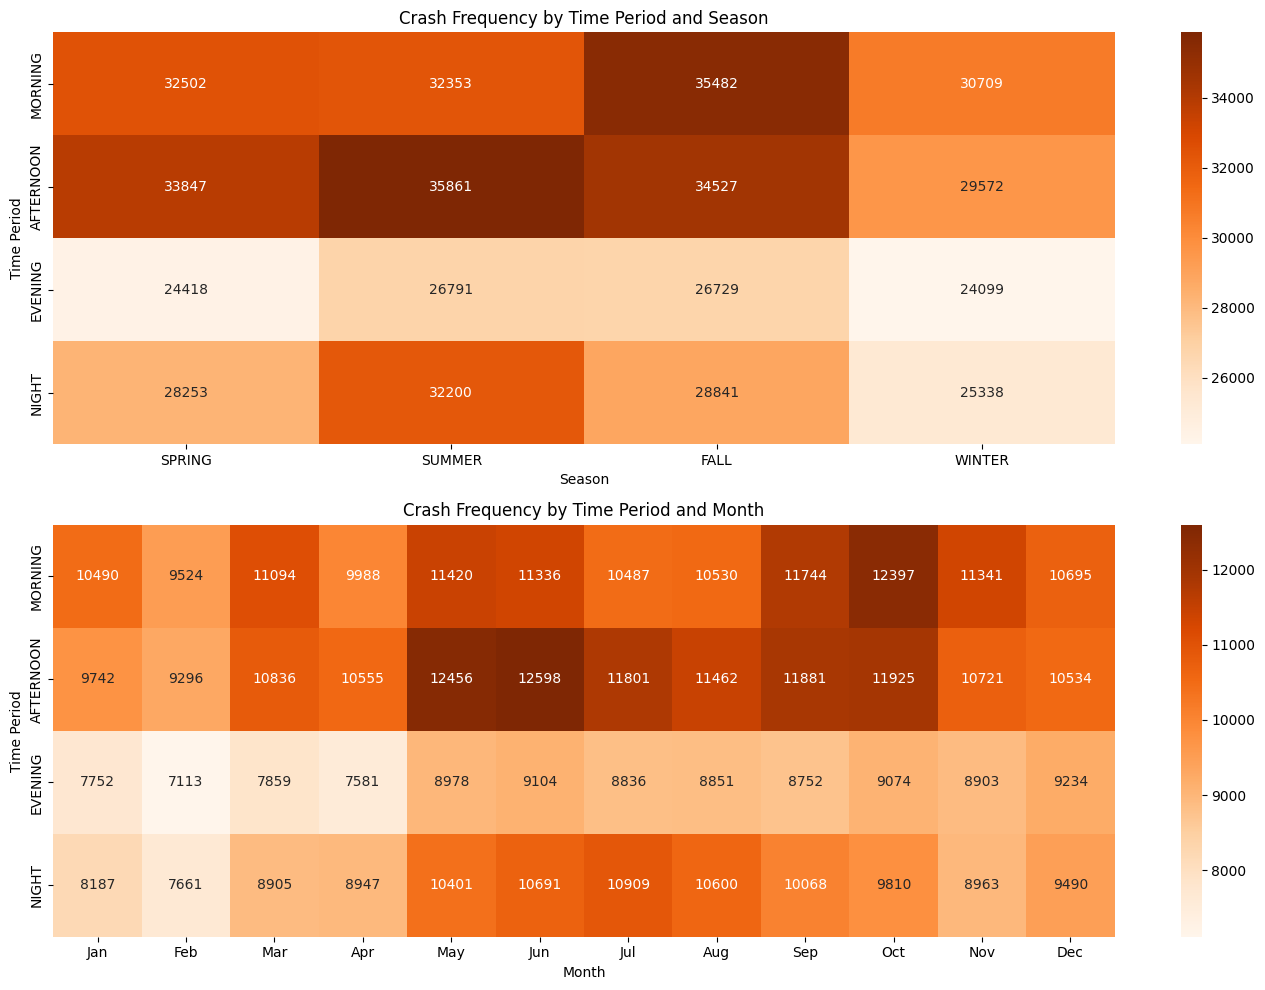

In [17]:
#Heatmap Season and Time-Period + Month and Time-Period

# 1. Season and Time-Period
time_season_ct = (
    merged_df_master
    .groupby(['time_period', 'season'])['collision_id']
    .nunique()
    .unstack()
)

# Fix order Time-Period
time_order = ['MORNING', 'AFTERNOON', 'EVENING', 'NIGHT']
time_season_ct = time_season_ct.reindex(time_order)

# Fix order Season
season_order = ['SPRING', 'SUMMER', 'FALL', 'WINTER']
time_season_ct = time_season_ct[season_order]

# 2. Month and Time-Period
month_time_analysis = merged_df_master.copy()

#Convert to month name
month_names = {
    1:'Jan', 2:'Feb', 3:'Mar', 4:'Apr',
    5:'May', 6:'Jun', 7:'Jul', 8:'Aug',
    9:'Sep', 10:'Oct', 11:'Nov', 12:'Dec'
}

month_time_analysis['month_name'] = (
    month_time_analysis['month'].map(month_names)
)

month_time_ct = (
    month_time_analysis
    .groupby(['time_period', 'month_name'])['collision_id']
    .nunique()
    .unstack()
)

# Fix order: Time-Period
month_time_ct = month_time_ct.reindex(time_order)

# Fix order: Month
month_order = [
    'Jan', 'Feb', 'Mar', 'Apr',
    'May', 'Jun', 'Jul', 'Aug',
    'Sep', 'Oct', 'Nov', 'Dec'
]

month_time_ct = month_time_ct[month_order]

# Create Subplots
fig, axes = plt.subplots(
    2, 1,
    figsize=(14,10)
)

# Heatmap 1: Season and Time-Period
sns.heatmap(
    time_season_ct,
    annot=True,
    fmt='d',
    cmap='Oranges',
    ax=axes[0]
)

axes[0].set_title('Crash Frequency by Time Period and Season')
axes[0].set_xlabel('Season')
axes[0].set_ylabel('Time Period')

# Heatmap 2: Month and Time-Period
sns.heatmap(
    month_time_ct,
    annot=True,
    fmt='d',
    cmap='Oranges',
    ax=axes[1]
)

axes[1].set_title('Crash Frequency by Time Period and Month')
axes[1].set_xlabel('Month')
axes[1].set_ylabel('Time Period')

# Layout
plt.tight_layout()
plt.show()

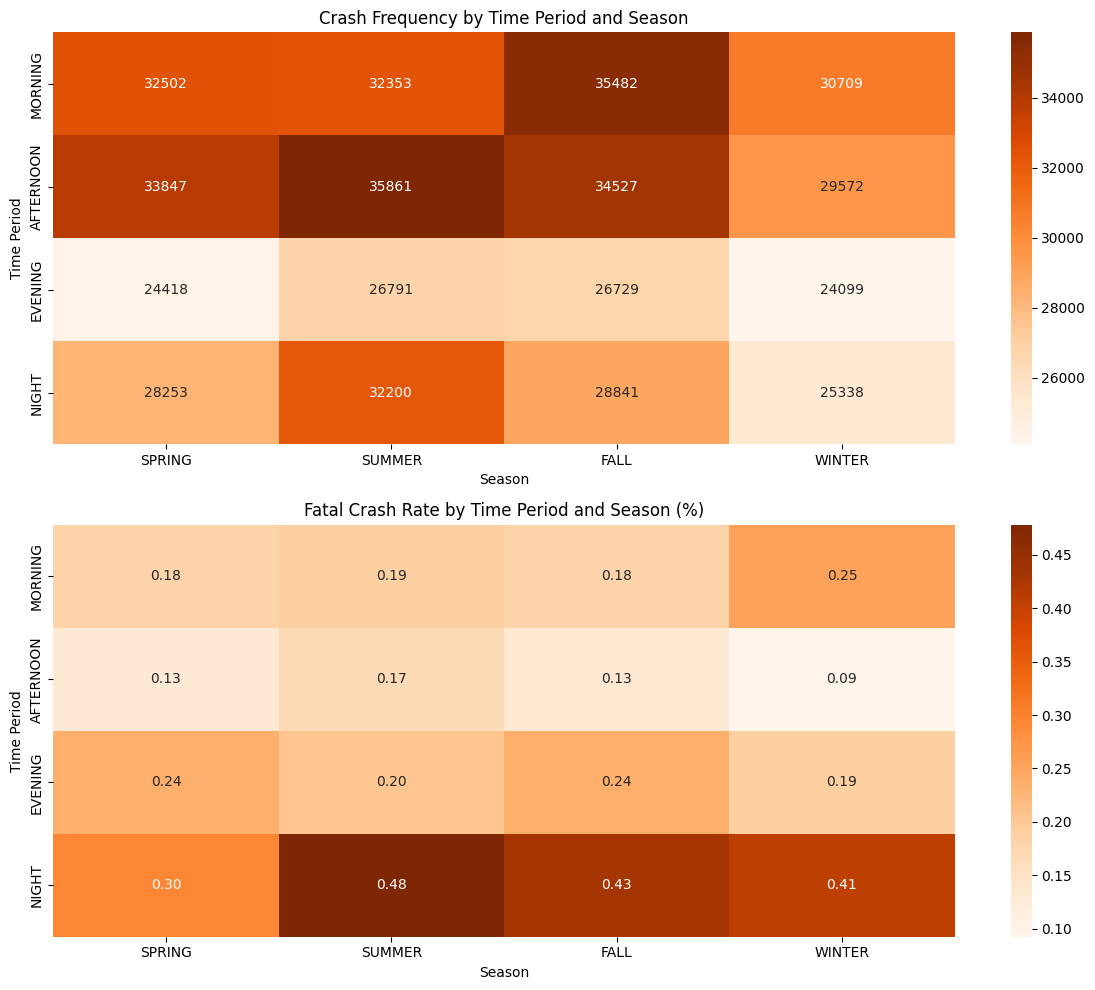

In [18]:
# Heatmaps:Crash Frequency vs Fatal Crash Rate by Time Period and Season

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

time_season_analysis = merged_df_master.copy()

# Fix time-period and season orders
time_order = ['MORNING', 'AFTERNOON', 'EVENING', 'NIGHT']
season_order = ['SPRING', 'SUMMER', 'FALL', 'WINTER']


# 1. Crash Frequency by Time Period and Season
crash_freq_time_season = (
    time_season_analysis
    .groupby(['time_period', 'season'])['collision_id']
    .nunique()
    .unstack()
)

crash_freq_time_season = crash_freq_time_season.reindex(time_order)
crash_freq_time_season = crash_freq_time_season[season_order]


# 2. Fatal Crash Rate by Time Period and Season
fatal_rate_time_season = (
    time_season_analysis
    .groupby(['time_period', 'season'])['fatal_crash']
    .mean()
    .unstack()
)

fatal_rate_time_season = fatal_rate_time_season.reindex(time_order)
fatal_rate_time_season = fatal_rate_time_season[season_order] * 100


# Create 2 Heatmaps
fig, axes = plt.subplots(
    2, 1,
    figsize=(12, 10)
)

# Top: Crash Frequency
sns.heatmap(
    crash_freq_time_season,
    annot=True,
    fmt='d',
    cmap='Oranges',
    ax=axes[0]
)

axes[0].set_title('Crash Frequency by Time Period and Season')
axes[0].set_xlabel('Season')
axes[0].set_ylabel('Time Period')

# Bottom: Fatal Crash Rate
sns.heatmap(
    fatal_rate_time_season,
    annot=True,
    fmt='.2f',
    cmap='Oranges',
    ax=axes[1]
)

axes[1].set_title('Fatal Crash Rate by Time Period and Season (%)')
axes[1].set_xlabel('Season')
axes[1].set_ylabel('Time Period')

# Layout
plt.tight_layout()
plt.show()

## 2H: Heatmap of Fatal Rate + Severity Score by Time Period / Month and Day Type

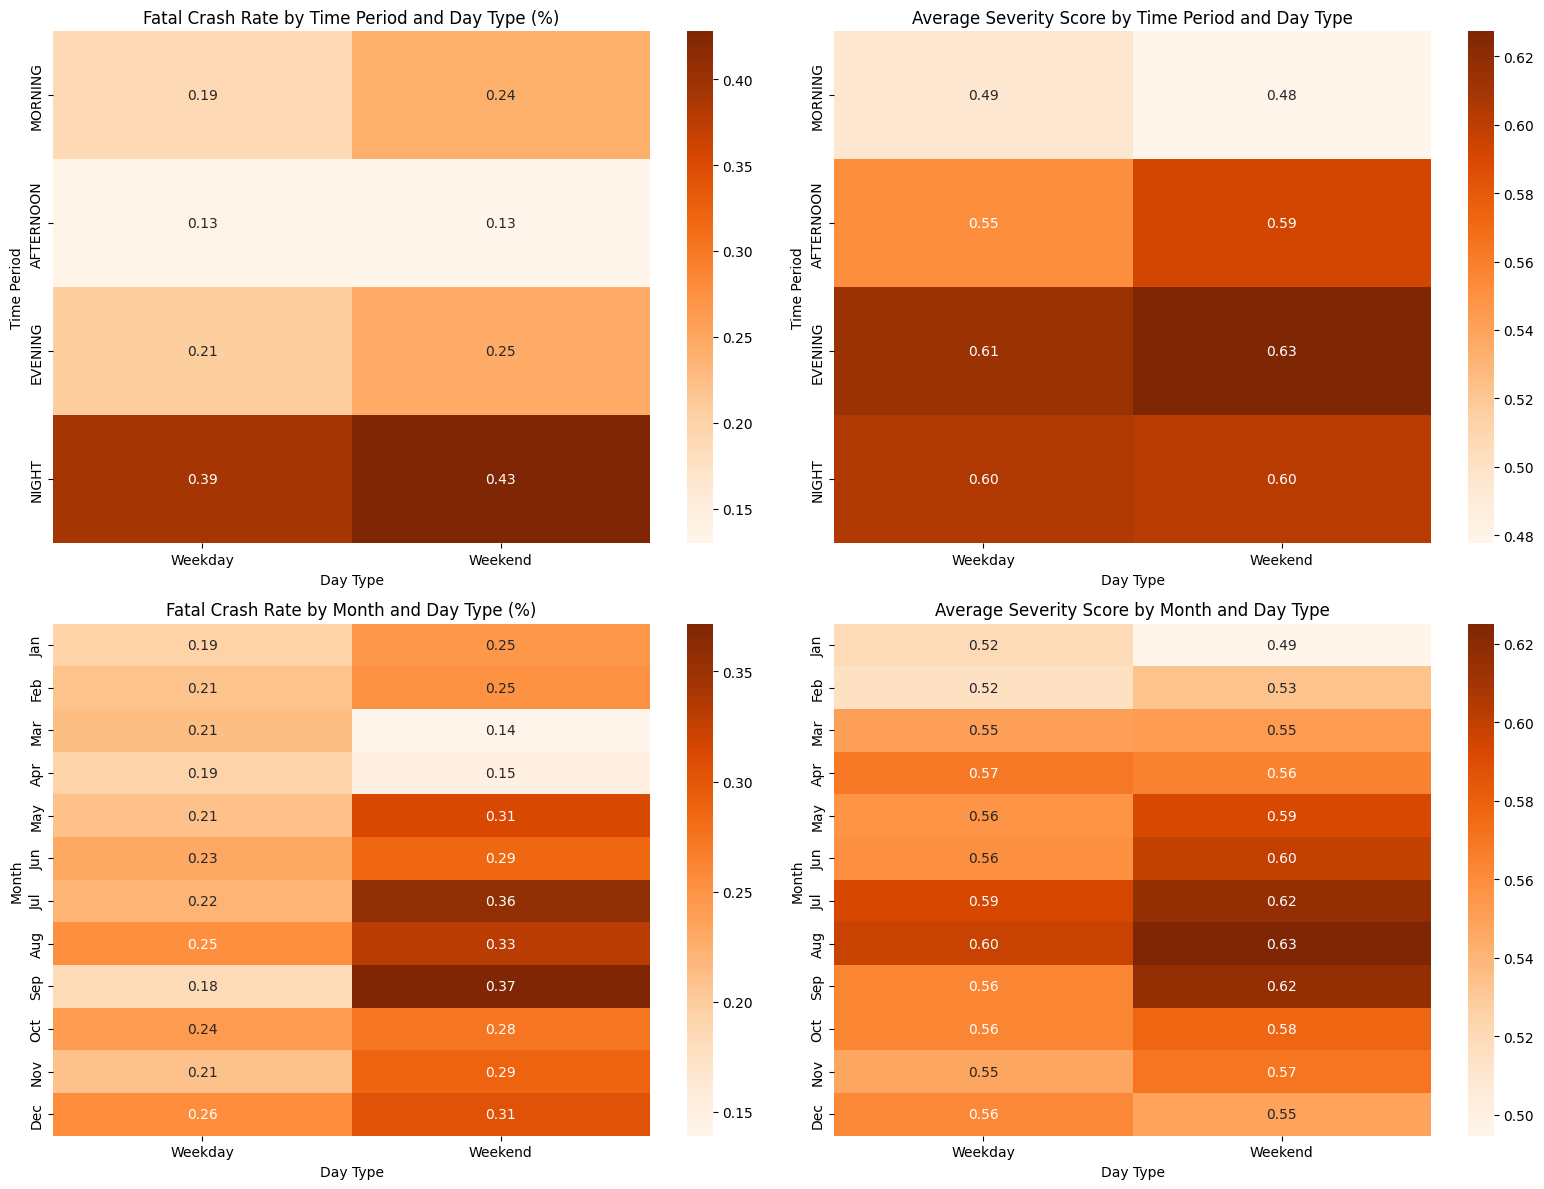

In [19]:
# Heatmaps:Fatal Rate + Severity Score by Time Period / Month and Day Type

heatmap_analysis = merged_df_master.copy()

# Weekday / Weekend label
heatmap_analysis['day_type'] = heatmap_analysis['is_weekend'].map({
    0: 'Weekday',
    1: 'Weekend'
})

# Month names
month_names = {
    1:'Jan', 2:'Feb', 3:'Mar', 4:'Apr',
    5:'May', 6:'Jun', 7:'Jul', 8:'Aug',
    9:'Sep', 10:'Oct', 11:'Nov', 12:'Dec'
}

heatmap_analysis['month_name'] = (
    heatmap_analysis['month'].map(month_names)
)

# Fix time-period and month orders
time_order = ['MORNING', 'AFTERNOON', 'EVENING', 'NIGHT']

month_order = [
    'Jan', 'Feb', 'Mar', 'Apr',
    'May', 'Jun', 'Jul', 'Aug',
    'Sep', 'Oct', 'Nov', 'Dec'
]

day_order = ['Weekday', 'Weekend']

# 1. Fatal Rate by Time Period
time_fatal_ct = (
    heatmap_analysis
    .groupby(['time_period', 'day_type'])['fatal_crash']
    .mean()
    .unstack()
)

time_fatal_ct = time_fatal_ct.reindex(time_order)
time_fatal_ct = time_fatal_ct[day_order] * 100

# 2. Severity Score by Time Period
time_severity_ct = (
    heatmap_analysis
    .groupby(['time_period', 'day_type'])['severity_score']
    .mean()
    .unstack()
)

time_severity_ct = time_severity_ct.reindex(time_order)
time_severity_ct = time_severity_ct[day_order]

# 3. Fatal Rate by Month
month_fatal_ct = (
    heatmap_analysis
    .groupby(['month_name', 'day_type'])['fatal_crash']
    .mean()
    .unstack()
)

month_fatal_ct = month_fatal_ct.reindex(month_order)
month_fatal_ct = month_fatal_ct[day_order] * 100

# 4. Severity Score by Month
month_severity_ct = (
    heatmap_analysis
    .groupby(['month_name', 'day_type'])['severity_score']
    .mean()
    .unstack()
)

month_severity_ct = month_severity_ct.reindex(month_order)
month_severity_ct = month_severity_ct[day_order]

# Create 2 x 2 Heatmaps
fig, axes = plt.subplots(
    2, 2,
    figsize=(16, 12)
)

# Heatmap 1: Day-type and Time-period
sns.heatmap(
    time_fatal_ct,
    annot=True,
    fmt='.2f',
    cmap='Oranges',
    ax=axes[0, 0]
)

axes[0, 0].set_title(
    'Fatal Crash Rate by Time Period and Day Type (%)'
)
axes[0, 0].set_xlabel('Day Type')
axes[0, 0].set_ylabel('Time Period')


# Heatmap 2: Day-type and Time-period
sns.heatmap(
    time_severity_ct,
    annot=True,
    fmt='.2f',
    cmap='Oranges',
    ax=axes[0, 1]
)

axes[0, 1].set_title(
    'Average Severity Score by Time Period and Day Type'
)
axes[0, 1].set_xlabel('Day Type')
axes[0, 1].set_ylabel('Time Period')

# Heatmap 3: Day-type and Month
sns.heatmap(
    month_fatal_ct,
    annot=True,
    fmt='.2f',
    cmap='Oranges',
    ax=axes[1, 0]
)

axes[1, 0].set_title(
    'Fatal Crash Rate by Month and Day Type (%)'
)
axes[1, 0].set_xlabel('Day Type')
axes[1, 0].set_ylabel('Month')

# Heatmap 4: Day-type and Month
sns.heatmap(
    month_severity_ct,
    annot=True,
    fmt='.2f',
    cmap='Oranges',
    ax=axes[1, 1]
)

axes[1, 1].set_title(
    'Average Severity Score by Month and Day Type'
)
axes[1, 1].set_xlabel('Day Type')
axes[1, 1].set_ylabel('Month')

# Layout
plt.tight_layout()
plt.show()

## 2I: Heatmap of Season and Borough + Month and Borough

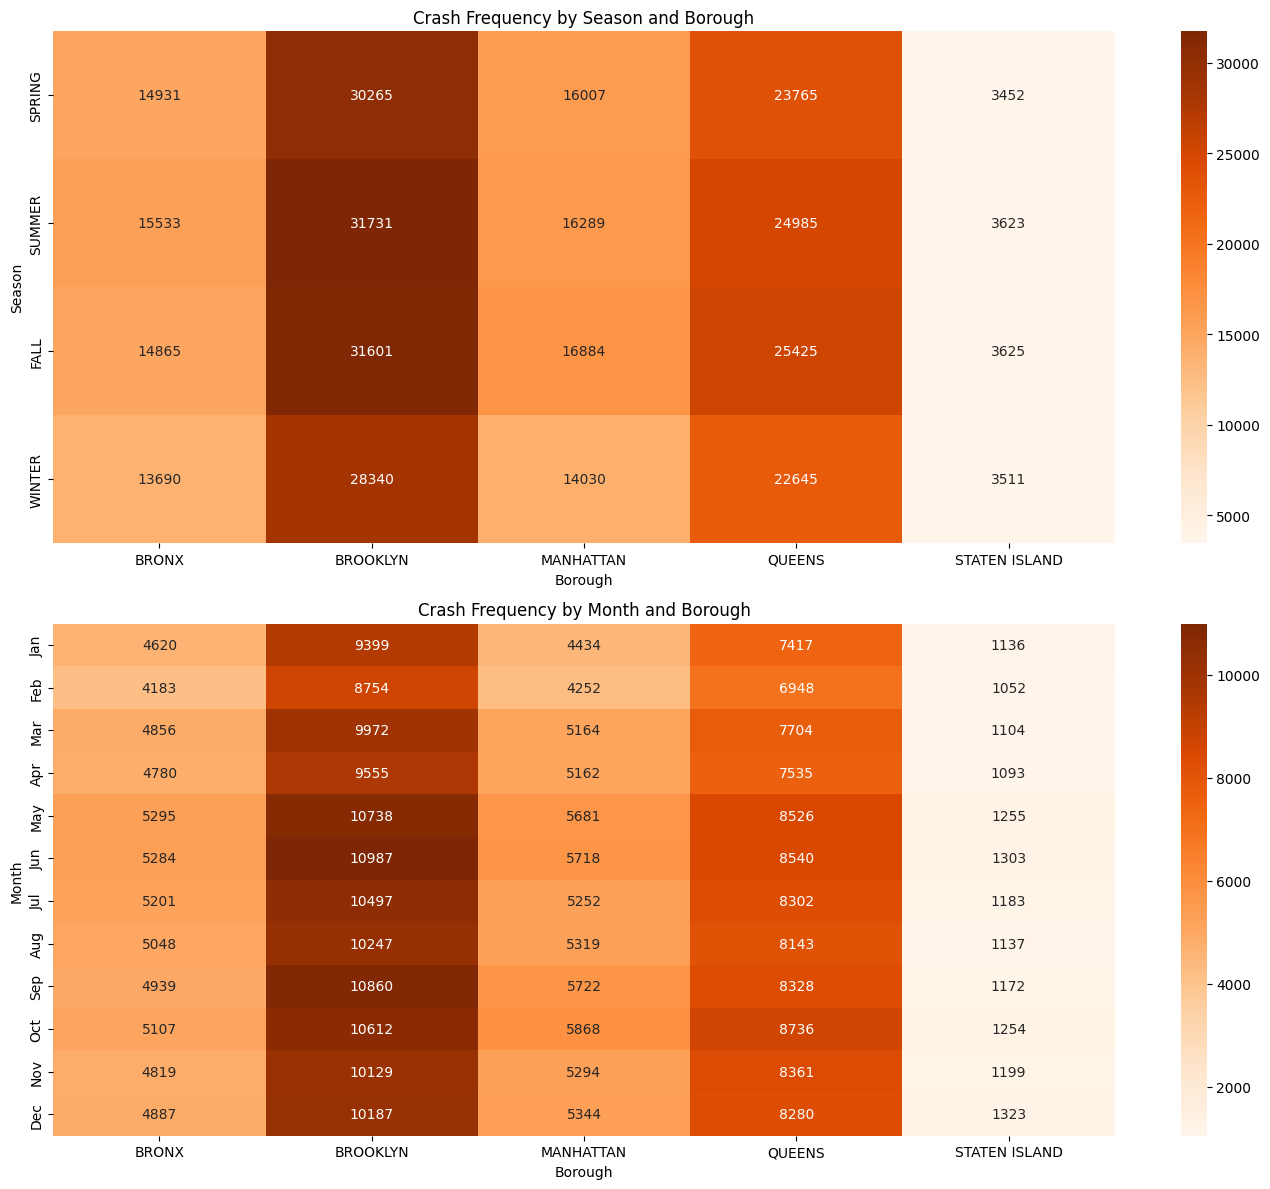

In [20]:
# Season and Borough Heatmap + Month and Borough Heatmap

# Create month names
month_names = {
    1:'Jan', 2:'Feb', 3:'Mar', 4:'Apr',
    5:'May', 6:'Jun', 7:'Jul', 8:'Aug',
    9:'Sep', 10:'Oct', 11:'Nov', 12:'Dec'
}

# Add month_name column to month_vs_crashes
month_vs_crashes['month_name'] = (
    month_vs_crashes['month'].map(month_names)
)

# Season x Borough Crosstab
# To use 'nunique' instead of 'count' we use groupby
season_borough_ct = (
    season_vs_crashes
    .groupby(['season', 'borough'])['collision_id']
    .nunique()
    .unstack()
)

# Fix Season order
season_order = ['SPRING', 'SUMMER', 'FALL', 'WINTER']
season_borough_ct = season_borough_ct.reindex(season_order)

# Month x Borough Crosstab
month_borough_ct = (
    month_vs_crashes
    .groupby(['month_name', 'borough'])['collision_id']
    .nunique()
    .unstack()
)

# Fix Month order
month_order = [
    'Jan', 'Feb', 'Mar', 'Apr',
    'May', 'Jun', 'Jul', 'Aug',
    'Sep', 'Oct', 'Nov', 'Dec'
]

month_borough_ct = month_borough_ct.reindex(month_order)

# Fix Borough order
borough_order = [
    'BRONX',
    'BROOKLYN',
    'MANHATTAN',
    'QUEENS',
    'STATEN ISLAND'
]

season_borough_ct = season_borough_ct[borough_order]
month_borough_ct = month_borough_ct[borough_order]

# Create subplots
fig, axes = plt.subplots(
    2, 1,
    figsize=(14, 12)
)

# Heatmap 1: Season and Borough
sns.heatmap(
    season_borough_ct,
    annot=True,
    fmt='d',
    cmap='Oranges',
    ax=axes[0]
)

axes[0].set_title('Crash Frequency by Season and Borough')
axes[0].set_xlabel('Borough')
axes[0].set_ylabel('Season')

# Heatmap 2: Month and Borough
sns.heatmap(
    month_borough_ct,
    annot=True,
    fmt='d',
    cmap='Oranges',
    ax=axes[1]
)

axes[1].set_title('Crash Frequency by Month and Borough')
axes[1].set_xlabel('Borough')
axes[1].set_ylabel('Month')

#  layout
plt.tight_layout()
plt.show()

## 2J: Fatality Rate per ZIP code

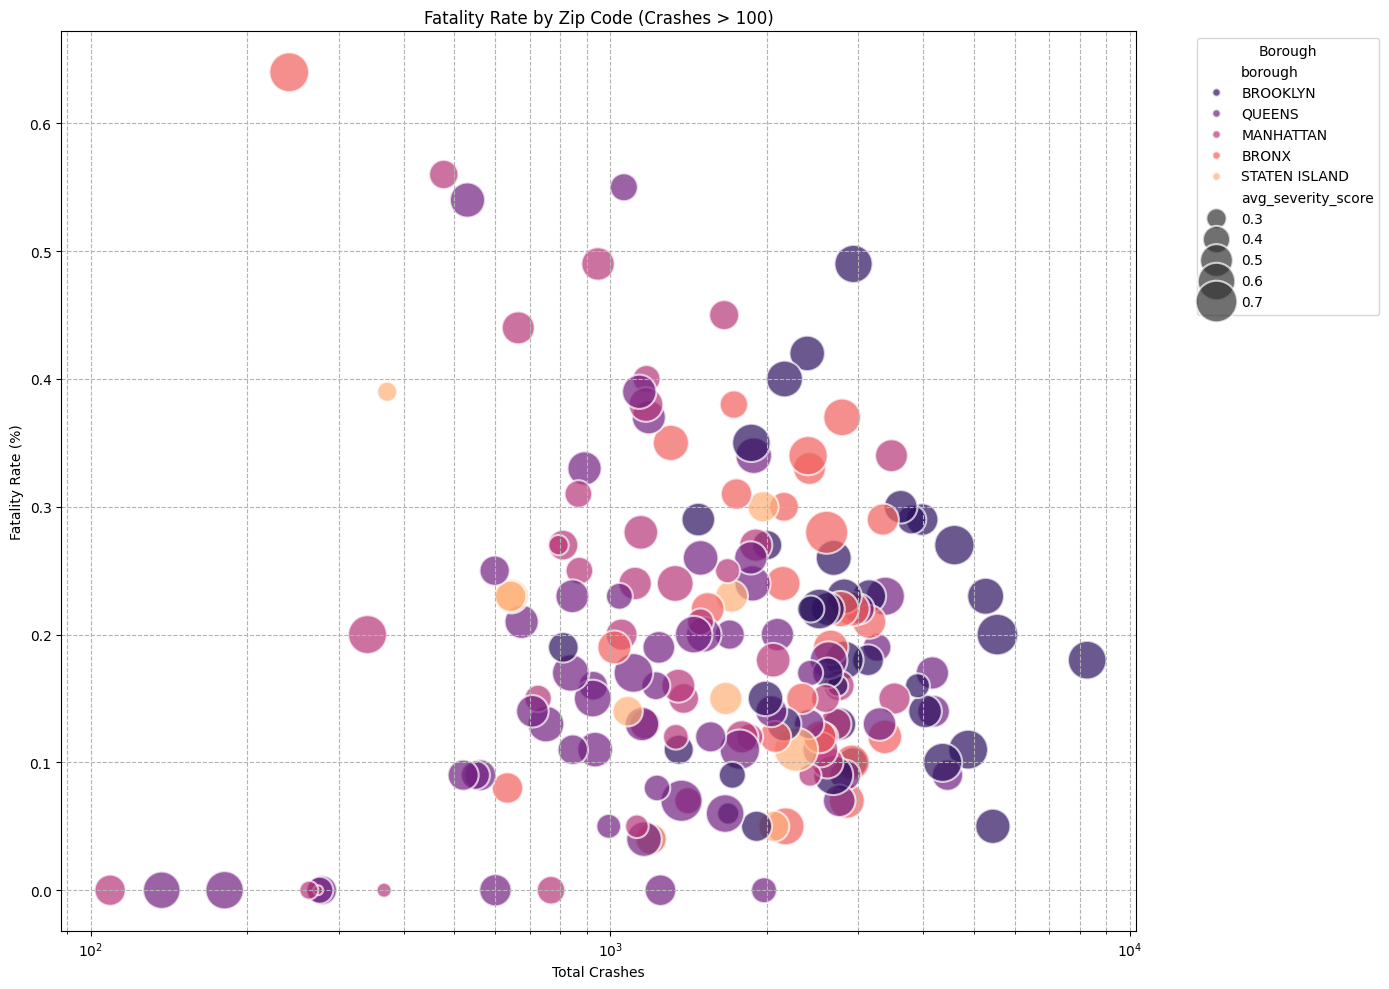

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate average severity score per zip code
avg_severity_per_zip = merged_df_master[merged_df_master['zip'] != 'UNKNOWN']\
    .groupby('zip')['severity_score']\
    .mean()\
    .reset_index(name='avg_severity_score')

# Determine the dominant borough for each zip code
# First, count occurrences of each borough within each zip code
borough_counts = merged_df_master[merged_df_master['zip'] != 'UNKNOWN']\
    .groupby(['zip', 'borough'])['collision_id']\
    .nunique()\
    .reset_index()

# Then, find the borough with the maximum count for each zip code
dominant_borough_per_zip = borough_counts.loc[borough_counts.groupby('zip')['collision_id'].idxmax()]\
    .rename(columns={'collision_id': 'borough_crash_count'})

# Merge all the dataframes
plot_df = pd.merge(zip_counts, zip_fatality_rates, on='zip', how='inner')
plot_df = pd.merge(plot_df, avg_severity_per_zip, on='zip', how='inner')
plot_df = pd.merge(plot_df, dominant_borough_per_zip[['zip', 'borough']], on='zip', how='left')

# Filter out zip codes with less than 100 crashes
filtered_plot_df = plot_df[plot_df['crash_count'] >= 100].copy()

# Create the scatter plot
plt.figure(figsize=(14, 10))
sns.scatterplot(
    data=filtered_plot_df,
    x='crash_count',
    y='fatality_rate_percent',
    size='avg_severity_score',
    hue='borough',
    sizes=(50, 1000), # Adjust size range for better visualization
    alpha=0.7,
    palette='magma' # Choose a color palette
)

plt.title('Fatality Rate by Zip Code (Crashes > 100)')
plt.xlabel('Total Crashes')
plt.ylabel('Fatality Rate (%)')
plt.xscale('log') # Use a log scale for crash_count to better distribute points
plt.grid(True, which="both", ls="--", c='0.7')
plt.legend(title='Borough', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# Part 3: Logistic / Clustering Models

## 3A: Logistic Model

In [22]:
# Defining the random state for each subsequent cell execution
random_state = 42

# Preparing the dataset for the logistic regression and clustering model (lr for logistic regression)
merged_df_lr = merged_df_master.copy()

# Defining a function to generalize vehicle types
def generalize_vehicle_type(vehicle_type):
    vehicle_type = str(vehicle_type).upper()
    if 'TRUCK' in vehicle_type or 'PICKUP' in vehicle_type or 'VAN' in vehicle_type:
        return 'TRUCK_VAN'
    elif 'MOTORCYCLE' in vehicle_type or 'BIKE' in vehicle_type or 'SCOOTER' in vehicle_type:
        return 'MOTORCYCLE_BIKE'
    elif 'SEDAN' in vehicle_type or 'STATION WAGON' in vehicle_type or 'SPORT UTILITY' in vehicle_type or 'SUV' in vehicle_type:
        return 'CAR_SUV'
    elif 'BUS' in vehicle_type:
        return 'BUS'
    elif 'TAXI' in vehicle_type:
        return 'TAXI'
    elif 'AMBULANCE' in vehicle_type or 'FIRE' in vehicle_type or 'EMERGENCY' in vehicle_type:
        return 'EMERGENCY_VEHICLE'
    elif 'UNKNOWN' in vehicle_type or 'OTHER' in vehicle_type or vehicle_type == 'NAN' or vehicle_type == '':
        return 'UNKNOWN_OTHER'
    else:
        return 'OTHER_VEHICLE'

# Defining a function to generalize impact points
def generalize_impact_point(impact_point):
    impact_point = str(impact_point).upper()
    if 'FRONT' in impact_point:
        return 'FRONT_IMPACT'
    elif 'REAR' in impact_point:
        return 'REAR_IMPACT'
    elif 'SIDE' in impact_point:
        return 'SIDE_IMPACT'
    elif 'UNDERCARRIAGE' in impact_point:
        return 'UNDERCARRIAGE_IMPACT'
    elif 'OVERTURNED' in impact_point:
        return 'OVERTURNED'
    elif 'UNKNOWN' in impact_point or 'OTHER' in impact_point or impact_point == 'NAN' or impact_point == '':
        return 'UNKNOWN_OTHER_IMPACT'
    else:
        return 'OTHER_IMPACT'

# Defining a function to generalize officially reported contributing factors
def generalize_factor(factor):
    factor = str(factor).upper()
    if 'ALCOHOL' in factor or 'DRUG' in factor or 'PRESCRIPTION' in factor:
        return 'DRIVING_UNDER_INFLUENCE'
    elif 'CELL PHONE' in factor or 'TEXTING' in factor or 'ELECTRONIC' in factor or 'NAVIGATION' in factor or 'HEADPHONES' in factor:
        return 'DISTRACTED_DEVICE'
    elif 'INATTENTION' in factor or 'DISTRACTION' in factor or 'OUTSIDE' in factor or 'PASSENGER' in factor or 'EATING' in factor:
        return 'DISTRACTED_DRIVING'
    elif 'ASLEEP' in factor or 'FATIGUED' in factor or 'DROWSY' in factor:
        return 'FATIGUED'
    elif 'CONSCIOUSNESS' in factor or 'ILLNES' in factor or 'DISABILITY' in factor:
        return 'MEDICAL_REASON'
    elif 'AGGRESSIVE' in factor or 'ROAD RAGE' in factor or 'SPEED' in factor:
        return 'AGGRESSIVE_DRIVING'
    elif 'INEXPERIENCE' in factor:
        return 'DRIVER_INEXPERIENCE'
    elif 'YIELD' in factor or 'RIGHT-OF-WAY' in factor:
        return 'FAILURE_TO_YIELD'
    elif 'TRAFFIC CONTROL' in factor:
        return 'TRAFFIC_CONTROL'
    elif 'FOLLOWING TOO CLOSELY' in factor:
        return 'TAILGATING'
    elif 'PASSING' in factor or 'LANE' in factor or 'TURNING IMPROPERLY' in factor or 'BACKING' in factor:
        return 'IMPROPER_MANEUVER'
    elif 'GLARE' in factor or 'VIEW' in factor or 'TINTED' in factor or 'WINDSHIELD' in factor or 'HEADLIGHTS' in factor or 'LIGHTING' in factor:
        return 'VISIBILITY'
    elif 'PAVEMENT' in factor or 'SLIPPERY' in factor or 'OBSTRUCTION' in factor or 'DEBRIS' in factor or 'SHOULDERS' in factor or 'LANE MARKING' in factor:
        return 'ROAD_CONDITIONS'
    elif 'BRAKES' in factor or 'TIRE' in factor or 'STEERING' in factor or 'ACCELERATOR' in factor or 'TOW HITCH' in factor or 'VEHICULAR' in factor:
        return 'VEHICLE_DEFECT'
    elif 'UNSPECIFIED' in factor or 'UNKNOWN' in factor:
        return 'UNKNOWN'
    else:
        return 'OTHER'


# Applying the generalization functions to each respective column
merged_df_lr['vehicle_type'] = merged_df_lr['vehicle_type_vehicle'].apply(generalize_vehicle_type)
merged_df_lr['impact_point'] = merged_df_lr['impact_point'].apply(generalize_impact_point)
merged_df_lr['factor'] = merged_df_lr['factor'].apply(generalize_factor)

# Selecting the relevant columns using the new generalized categories
merged_df_lr = merged_df_lr[['vehicle_type', 'factor', 'driver_sex', 'license_status', 'impact_point', 'borough', 'time_period', 'season', 'day_of_week', 'fatal_crash']]

# Selecting a random sample of 10,000 crashes from the previous 5 years to minimize glitches, runtime, and RAM failures
sampled_df = merged_df_lr.sample(n=10000, random_state=random_state)

# Setting the independent variables (what we predict could be contributing factors)
X = sampled_df[['vehicle_type', 'factor', 'driver_sex', 'license_status', 'impact_point', 'borough', 'time_period', 'season', 'day_of_week',]]

# Converting categorical variables to numerical using one-hot encoding (creating new columns with binary values based on whether a row contains a certain value or not)
X_encoded = pd.get_dummies(X).astype(int)

# Performing a logistic regression to determine most impactful factors on whether a crash was fatal or not

# Using the encoded dataframe for correlation
corr = X_encoded.corr().abs()

# Dropping columns that have a perfect -1 or 1 correlation to fatalities
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
to_drop = [column for column in upper.columns if any(upper[column] == 1)]
X_processed = X_encoded.drop(columns=to_drop)

# Dropping data that is "unknown" or "other" to reduce unhelpful analysis
X_processed = X_processed.drop(columns=[
    'vehicle_type_UNKNOWN_OTHER',
    'vehicle_type_OTHER_VEHICLE',
    'driver_sex_UNKNOWN',
    'driver_sex_U',
    'license_status_UNKNOWN',
    'borough_UNKNOWN',
    'impact_point_UNKNOWN_OTHER_IMPACT',
    'impact_point_OTHER_IMPACT',
    'impact_point_OTHER',
    'factor_UNKNOWN',
    'factor_OTHER'
], errors='ignore')

# Dropping columns where every single value is the same
constant_cols = [c for c in X_processed.columns if X_processed[c].nunique() <= 1]
X_processed = X_processed.drop(columns=constant_cols, errors='ignore')

# Adding a constant to the linear regression model for better accuracy
X_processed = sm.add_constant(X_processed, has_constant='add')
# Setting the 'fatal_crash' column as the dependent variable
Y = sampled_df[['fatal_crash']]

# Converting Y values into a 1D array for sklearn comprehension
Y = Y.values.ravel()

# Splitting and scaling the data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X_processed, Y, test_size=0.2, random_state=random_state)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Creating a sklearn logistic regression prediction model with a maximum of 1000 iterations
log_model = LogisticRegression(max_iter=1000, class_weight='balanced')
log_model.fit(X_train_scaled, y_train)
log_predictions = log_model.predict(X_test_scaled)
log_accuracy = accuracy_score(y_test, log_predictions)
print(f"Logistic Regression Accuracy: {log_accuracy * 100:.2f}%")
print()
print(f"Full Classification Report:\n {classification_report(y_test, log_predictions)}")
print()

# Running a statsmodels logistic regression using bfgs: Broyden–Fletcher–Goldfarb–Shanno algorithm (faster and more efficient)
crash_logit = sm.Logit(Y,X_processed).fit(method='bfgs', maxiter=1000)
print(crash_logit.summary())
# Despite having a sample from the past 5 years, there are not enough fatal crashes for the coefficients and p-values to be significant.
# Therefore the coefficients here are not extremely accurate, but still make for an interesting estimated analysis


Logistic Regression Accuracy: 81.10%

Full Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.81      0.90      1997
           1       0.01      0.67      0.01         3

    accuracy                           0.81      2000
   macro avg       0.50      0.74      0.45      2000
weighted avg       1.00      0.81      0.89      2000


Optimization terminated successfully.
         Current function value: 0.013505
         Iterations: 200
         Function evaluations: 205
         Gradient evaluations: 205
                           Logit Regression Results                           
Dep. Variable:                      y   No. Observations:                10000
Model:                          Logit   Df Residuals:                     9951
Method:                           MLE   Df Model:                           48
Date:                Wed, 18 Nov 2026   Pseudo R-squ.:                  0.2272
Time:                        20:28:

/usr/local/lib/python3.13/dist-packages/statsmodels/discrete/discrete_model.py:268: HessianInversionWarning: Inverting hessian failed, no bse or cov_params available
  mlefit = super().fit(


## 3B: Statistically Significant Coefficients/P-values

                           Feature  Coefficient  P-value
13        factor_IMPROPER_MANEUVER    -5.926069      NaN
16               factor_TAILGATING    -5.010810      NaN
18           factor_VEHICLE_DEFECT    -4.136761      NaN
20                    driver_sex_F    -3.948813      NaN
4                vehicle_type_TAXI    -3.929176      NaN
10  factor_DRIVING_UNDER_INFLUENCE     1.622220      NaN
14           factor_MEDICAL_REASON     2.282011      NaN
22         license_status_LICENSED     3.248004      NaN
24       license_status_UNLICENSED     4.014567      NaN
23           license_status_PERMIT     4.322539      NaN


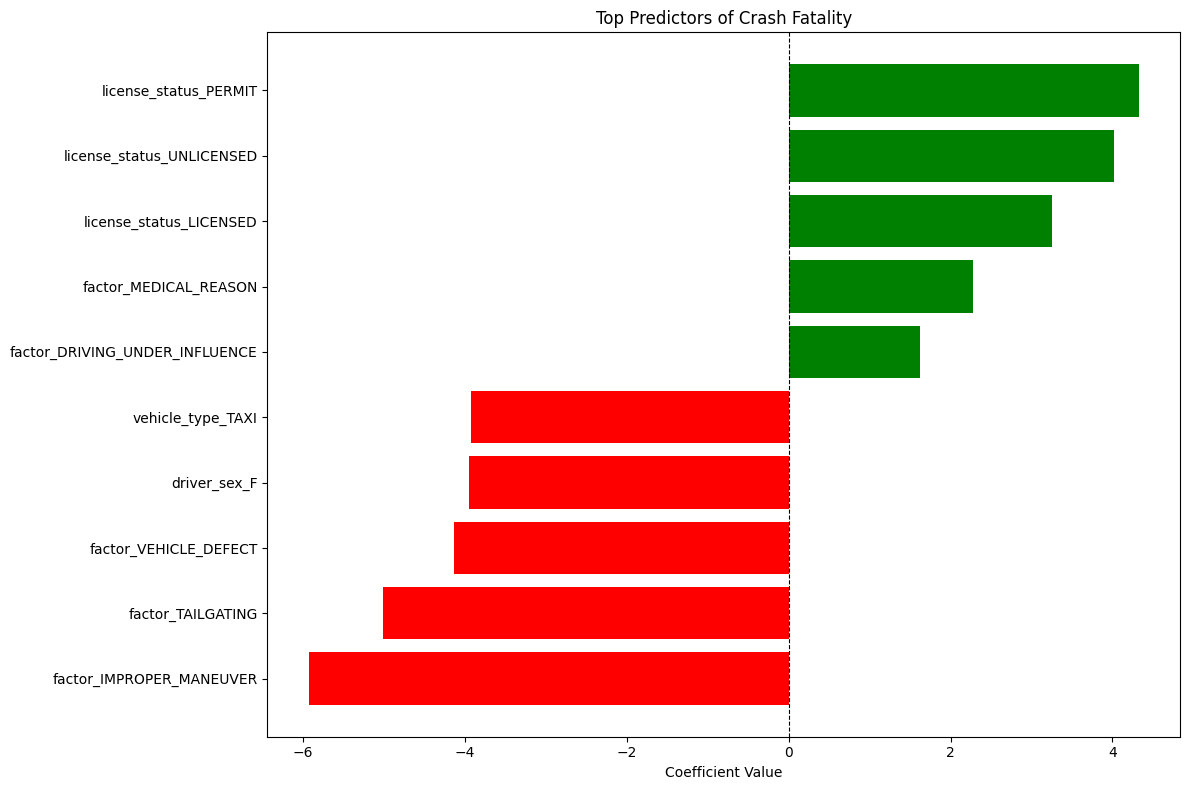

In [23]:
# Create DataFrame with all coefficients and p-values
all_coef_df = pd.DataFrame({
    'Feature': crash_logit.params.index[1:],
    'Coefficient': crash_logit.params.values[1:],
    'P-value': crash_logit.pvalues.values[1:]
})

# Filter for statistically significant predictors (P-value < 0.05)
significant_coef_df = all_coef_df[all_coef_df['P-value'] < 0.05].sort_values('Coefficient')

# To address potential clutter and show more than just one feature if the p-value filter is too strict,
# we will plot the top 5 most positive and top 5 most negative coefficients.
# If the number of significant features is small, this provides a more informative plot.
if len(significant_coef_df) < 10: # If less than 10 significant features, consider top/bottom from all
    top_positive = all_coef_df.nlargest(5, 'Coefficient')
    top_negative = all_coef_df.nsmallest(5, 'Coefficient')
    # Combine and sort, removing duplicates if a feature appears in both (e.g., if coefficient is 0)
    coef_df_to_plot = pd.concat([top_negative, top_positive]).drop_duplicates().sort_values('Coefficient')
else:
    coef_df_to_plot = significant_coef_df

plt.figure(figsize=(12, 8))
plt.barh(coef_df_to_plot['Feature'], coef_df_to_plot['Coefficient'],
         color=['red' if x < 0 else 'green' for x in coef_df_to_plot['Coefficient']])
plt.xlabel('Coefficient Value')
plt.title('Top Predictors of Crash Fatality')
plt.axvline(x=0, color='black', linestyle='--', linewidth=0.8)
plt.tight_layout()
print(coef_df_to_plot)
plt.show()


## 3C: K-Means Clustering

The optimal number of clusters is 6


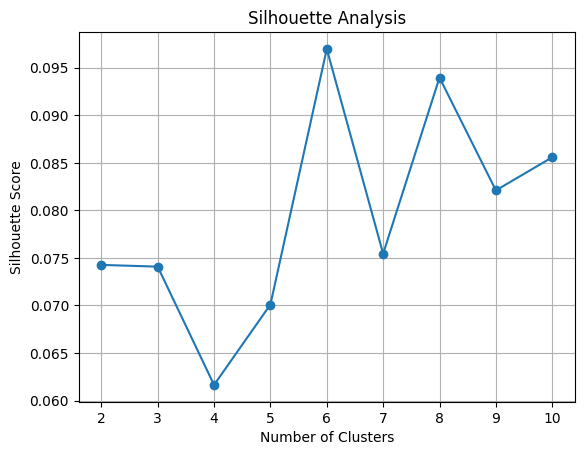

In [24]:
# Assigning data for clustering, using encoded values
X_cluster = X_encoded.copy()

# Dropping columns with overly dominating values that skew the clustering

# Dropping entire 'factor' and 'driver_sex' column since it overbears the clusters
X_cluster = X_encoded.drop(columns=[
    c for c in X_encoded.columns
    if c.startswith('factor_') or c.startswith('driver_sex_')
], errors='ignore').copy()
# Dropping unknown or 'other' values
X_cluster = X_cluster.drop(columns=[
    'vehicle_type_UNKNOWN_OTHER',
    'vehicle_type_OTHER_VEHICLE',
    'license_status_UNKNOWN',
    'borough_UNKNOWN',
    'impact_point_UNKNOWN_OTHER_IMPACT',
    'impact_point_OTHER_IMPACT',
    'impact_point_OTHER',
], errors='ignore')
X_cluster.dropna(inplace=True)

# Finding the optimal number of clusters (k) using a silhouette score analysis

# Setting range of 2 to 11 since there needs to be at least 2 clusters and we want a maximum of 10
k_range = range(2, 11)
scores = []
for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=random_state)
    labels = kmeans.fit_predict(X_cluster)
    scores.append(silhouette_score(X_cluster, labels))

k = list(k_range)[scores.index(max(scores))]
print(f"The optimal number of clusters is {k}")

plt.plot(range(2, 11), scores, marker='o')
plt.xlabel('Number of Clusters')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Analysis')
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()


## 3D: Visualization of K-means clustering

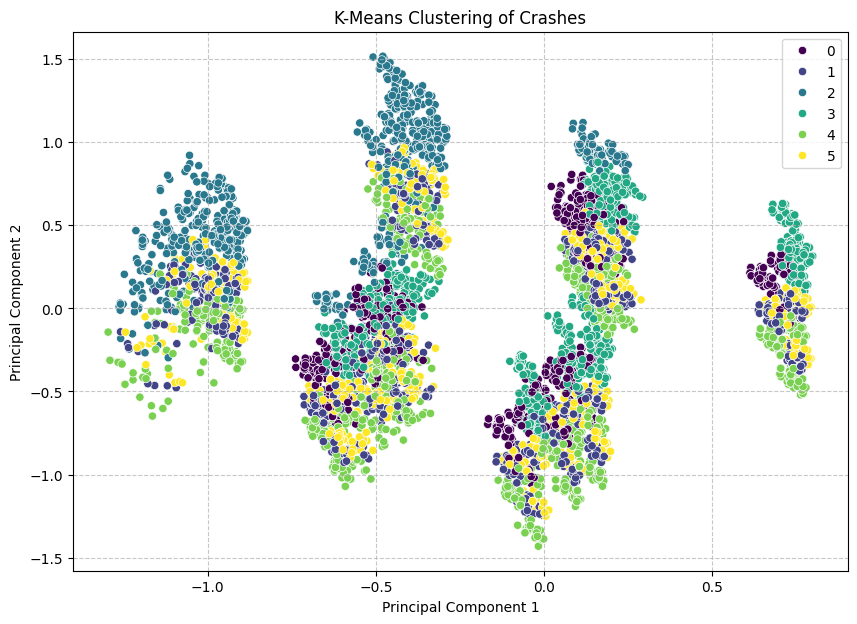

Cluster labels assigned to each crash:
[5 0 3 ... 4 2 3]

CLUSTER 0
Number of crashes: 1523
Fatality rate: 0.33%

Average characteristics:
vehicle_type_BUS                     0.013789
vehicle_type_CAR_SUV                 0.845043
vehicle_type_EMERGENCY_VEHICLE       0.005909
vehicle_type_MOTORCYCLE_BIKE         0.032830
vehicle_type_TAXI                    0.023638
vehicle_type_TRUCK_VAN               0.053841
license_status_LICENSED              0.703217
license_status_PERMIT                0.013132
license_status_UNLICENSED            0.011162
license_status_VALID                 0.000000
impact_point_FRONT_IMPACT            0.575837
impact_point_OVERTURNED              0.000657
impact_point_REAR_IMPACT             0.177938
impact_point_SIDE_IMPACT             0.093237
impact_point_UNDERCARRIAGE_IMPACT    0.001313
borough_BRONX                        0.119501
borough_BROOKLYN                     0.262640
borough_MANHATTAN                    0.098490
borough_QUEENS                   

In [25]:
#Assigning data for clustering and dropping null values (if they are there)
X_cluster = X_cluster
X_cluster.dropna(inplace=True)

#K-Means clustering, use (k) clusters since the silhouette score method says it's the optimal amount
kmeans = KMeans(n_clusters=k, random_state=random_state, n_init='auto')
cluster_labels = kmeans.fit_predict(X_cluster)

#PCA 2 Dimensional plotting
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_cluster)

# Creating clustering visualization
plt.figure(figsize=(10, 7))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=cluster_labels, palette='viridis', legend='full')
plt.title('K-Means Clustering of Crashes')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

print("Cluster labels assigned to each crash:")
print(cluster_labels)

sampled_df_clustered = sampled_df.copy()
sampled_df_clustered = sampled_df_clustered.loc[X_cluster.index]
sampled_df_clustered['Cluster'] = cluster_labels

# Adding cluster labels to X_cluster for easier grouping and mean calculation
X_cluster_with_labels = X_cluster.copy()
X_cluster_with_labels['Cluster'] = cluster_labels

# Outputting mean characteristics for each cluster, including a mean fatality rate
for i in range(k):
    print(f"\nCLUSTER {i}")
    cluster_original_data = sampled_df_clustered[sampled_df_clustered['Cluster'] == i]
    print(f"Number of crashes: {len(cluster_original_data)}")
    # Calculating mean fatality rate for each cluster
    print(f"Fatality rate: {cluster_original_data['fatal_crash'].mean():.2%}")
    cluster_characteristics = X_cluster_with_labels[X_cluster_with_labels['Cluster'] == i]
    print("\nAverage characteristics:")
    # Calculating mean for all columns except the 'Cluster' column, which was just added
    print(cluster_characteristics.drop(columns=['Cluster']).mean())
